# Préparation des données — Agritech Answers

**Étape 1 — Consolidation.** Produit le **dataset unique** qui servira de source de vérité aux étapes suivantes : nettoyage des six fichiers, construction du référentiel FAO, création des variables.

S'appuie sur `exploratory_data_analysis.ipynb` sans en refaire les constats.

| Constat de l'exploration | Conséquence ici |
|---|---|
| Tout se passe comme si le jeu A suivait une relation additive simple, de plafond R² ≈ 0,913 | Aucune variable créée ne devrait améliorer la prédiction — **vérifié en §8** |
| `Crop` sans effet mesurable (η² = 0,000006) | La recommandation exige un apport externe : c'est l'objet du §6 |
| `yield_df.csv` amputé de 76,8 % et gonflé par duplication | Référentiel rebâti depuis `yield.csv` ; `yield_df` sert de contrôle (§5) |
| `rainfall.csv` = normale climatique constante par pays | Écartée comme variable explicative |
| `temp.csv` : 7 534 couples à valeurs divergentes | Agrégation médiane **avant** jointure |

| § | Étape |
|---|---|
| 1-2 | Configuration, contrôle qualité des six fichiers |
| 3 | Nettoyage fichier par fichier |
| 4-5 | Panel FAO par jointures gauches, puis validation |
| 6 | Référentiel par culture |
| 7 | Enrichissement des parcelles et variables de parcelle |
| 8 | Validation hors échantillon, redondance, **retrait de deux colonnes** |
| 9 | Dictionnaire, contrôles et export du livrable |
| 10-11 | Figures du rapport métier, synthèse |

## 1. Configuration

In [ ]:
# Le projet est installe en mode editable par `uv sync`. Repli au cas ou le
# noyau selectionne ne serait pas celui du projet : on ajoute src/ au chemin.
try:
    import agritech  # noqa: F401
except ModuleNotFoundError:
    import sys
    from pathlib import Path
    _racine = next(p for p in [Path.cwd(), *Path.cwd().parents]
                   if (p / 'pyproject.toml').exists())
    sys.path.insert(0, str(_racine / 'src'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

from agritech import pipeline, preparation
from agritech.preparation import (
    COLONNES_DIFFUSEES,
    COLONNES_NON_RETENUES,
    COLONNES_REDONDANTES,
    COLONNES_REFERENCE,
    colonnes_constantes,
    controle,
)
from agritech.config import (
    BLUE,
    CONSOLIDATED_PARQUET_PATH,
    CONSOLIDATED_PATH,
    CROPS_WITHOUT_REFERENCE,
    CROP_MAPPING,
    CROP_REFERENCE_PATH,
    DATA_DICTIONARY_PATH,
    FAO_PANEL_PATH,
    GREEN,
    HG_PER_HA_TO_T_PER_HA,
    ORANGE,
    PROJECT_ROOT,
    RANDOM_STATE,
    SEUIL_FAIBLE_PLUIE_MM,
    TARGET,
)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 180)
pd.set_option('display.float_format', lambda v: format(v, ',.3f'))
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110

KEY_FAO = preparation.CLE_FAO

In [2]:
def controle(df, nom, cle=None):
    # Fiche de controle commune a tous les fichiers : volume, manquants, doublons
    ligne = {
        'fichier': nom,
        'lignes': len(df),
        'colonnes': df.shape[1],
        'cellules_nan': int(df.isna().sum().sum()),
        'colonnes_avec_nan': int((df.isna().sum() > 0).sum()),
        'doublons_stricts': int(df.duplicated().sum()),
    }
    ligne['doublons_sur_cle'] = int(df.duplicated(subset=cle).sum()) if cle else 0
    return ligne


def colonnes_constantes(df):
    # Colonnes a valeur unique : aucune information, donc supprimables
    return [col for col in df.columns if df[col].nunique(dropna=False) <= 1]

## 2. Chargement et contrôle qualité des six fichiers

Mêmes critères pour chaque fichier, avant tout traitement.

In [ ]:
sources = preparation.charger_sources()

# Les six tables gardent leurs noms d'origine : tout le reste du notebook les
# designe ainsi, et les sections d'analyse les relisent telles quelles.
parcelles = sources.parcelles
fao_brut = sources.fao
pesticides_brut = sources.pesticides
pluie_brut = sources.pluie
temperatures_brut = sources.temperatures
fusion_fournie = sources.fusion_fournie

etat_initial = pd.DataFrame([
    controle(parcelles, 'crop_yield.csv'),
    controle(fao_brut, 'yield.csv', KEY_FAO),
    controle(pesticides_brut, 'pesticides.csv', ['Area', 'Year']),
    controle(pluie_brut, 'rainfall.csv'),
    controle(temperatures_brut, 'temp.csv', ['country', 'year']),
    controle(fusion_fournie, 'yield_df.csv', KEY_FAO),
]).set_index('fichier')
etat_initial

> **Lecture.** `rainfall.csv` et `temp.csv` portent des valeurs manquantes déclarées ; `rainfall.csv` en masque six de plus sous forme de texte (`'..'`), invisibles à `isna()`. Les seuls doublons sur clé métier sont dans `temp.csv`, et par héritage dans `yield_df.csv`.

## 3. Nettoyage fichier par fichier

### 3.1 Jeu A — rendements physiquement impossibles

In [ ]:
avant = len(parcelles)
negatifs = parcelles[TARGET] < 0

parcelles = preparation.nettoyer_parcelles(parcelles)

print('Rendements negatifs supprimes :', f'{int(negatifs.sum()):,}',
      f'({100 * negatifs.mean():.4f} %)')
print('Lignes conservees :', f'{len(parcelles):,}', 'sur', f'{avant:,}')
print('Valeurs manquantes :', int(parcelles.isna().sum().sum()),
      '| doublons stricts :', int(parcelles.duplicated().sum()))

> Un rendement négatif est physiquement impossible : suppression, pour un volume négligeable. Les rendements faibles mais positifs sont **conservés** — parcelles sèches sans intrants, parfaitement plausibles. L'origine probable de ces valeurs est examinée en §8.4.

### 3.2 `temp.csv` — agréger avant de joindre

In [ ]:
temperatures = preparation.agreger_temperatures(temperatures_brut)

print('Avant agregation :', f'{len(temperatures_brut):,}', 'lignes |',
      'doublons sur (pays, annee) :',
      f'{int(temperatures_brut.duplicated(subset=["country", "year"]).sum()):,}',
      '| avg_temp manquants :', int(temperatures_brut['avg_temp'].isna().sum()))
print('Apres agregation et retrait des couples sans mesure :',
      f'{len(temperatures):,}', 'lignes |',
      'doublons :', int(temperatures.duplicated(subset=['Area', 'Year']).sum()))

> Correction décisive : agréger **après** la jointure aurait laissé la duplication fausser toute pondération. Médiane plutôt que moyenne, les écarts intra-couple atteignant 27,9 °C.

### 3.3 `rainfall.csv` — valeurs manquantes masquées en texte

In [ ]:
COL_PLUIE = 'average_rain_fall_mm_per_year'

# Recalcule ici pour l'affichage : c'est la mesure du probleme, pas sa correction
brut_normalise = pluie_brut.rename(columns=lambda c: c.strip())
masquees = pd.to_numeric(brut_normalise[COL_PLUIE], errors='coerce').isna()

pluie = preparation.nettoyer_pluie(pluie_brut)

print('Valeurs non convertibles revelees :', f'{int(masquees.sum()):,}',
      f'({100 * masquees.mean():.1f} %)')
print('Exemples de valeurs fautives :',
      brut_normalise.loc[masquees, COL_PLUIE].unique()[:3])
print('Lignes conservees :', f'{len(pluie):,}')

> Deux natures de manquants : **774 valeurs vides** que `isna()` détecte, et **6 encodées `'..'`** que seule la conversion numérique révèle. Supprimées plutôt qu'imputées : cette variable ne sert qu'à décrire les zones de culture dans la table de référence.

### 3.4 `yield.csv` et `pesticides.csv` — colonnes sans information

In [ ]:
print('yield.csv      — colonnes constantes :', colonnes_constantes(fao_brut))
print('pesticides.csv — colonnes constantes :', colonnes_constantes(pesticides_brut))
print('yield.csv      — Year identique a Year Code :',
      bool((fao_brut['Year'] == fao_brut['Year Code']).all()))

# On ne garde que les colonnes porteuses d'information
rendements = preparation.nettoyer_rendements(fao_brut)
pesticides = preparation.nettoyer_pesticides(pesticides_brut)

avant_filtre = len(fao_brut)
print()
print('rendements :', rendements.shape, '| pesticides :', pesticides.shape)
print('rendements <= 0 supprimes :', f'{avant_filtre - len(rendements):,}')

### 3.5 Valeurs extrêmes : recherche systématique

§3.1 n'a retiré que les rendements **physiquement impossibles**. Reste à vérifier qu'aucune autre valeur extrême ne subsiste — et, le cas échéant, à décider de son sort.

On applique la règle de Tukey à toutes les variables quantitatives des cinq jeux nettoyés : est considérée comme extrême une valeur hors de l'intervalle `[Q1 − 1,5 × IQR ; Q3 + 1,5 × IQR]`.

Une valeur extrême n'est pas une erreur. Il faut distinguer trois cas : une **saisie fautive**, qu'on corrige ou retire ; une **observation rare mais réelle**, qu'on conserve ; et une **queue de distribution**, qu'on conserve aussi, car l'écarter biaiserait le modèle vers le centre.

In [8]:
def regle_de_tukey(serie, etiquette, source):
    """Valeurs hors de [Q1 - 1,5 IQR ; Q3 + 1,5 IQR]."""
    s = serie.dropna().astype(float)
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    bas, haut = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    sous, sur = int((s < bas).sum()), int((s > haut).sum())
    return {'source': source, 'variable': etiquette, 'n': len(s),
            'min': s.min(), 'max': s.max(),
            'borne_basse': bas, 'borne_haute': haut,
            'sous': sous, 'sur': sur, 'part_%': round(100 * (sous + sur) / len(s), 4)}


# Les cinq jeux nettoyes. On exclut les annees et les codes : un millesime ou
# un identifiant n'a pas de valeur aberrante au sens statistique.
JEUX = {'jeu A': parcelles, 'temp.csv': temperatures, 'rainfall.csv': pluie,
        'yield.csv': rendements, 'pesticides.csv': pesticides}
IGNOREES = ('year', 'annee')

lignes = []
for source, table in JEUX.items():
    for colonne in table.select_dtypes(include='number').columns:
        if colonne.lower() in IGNOREES or 'code' in colonne.lower():
            continue
        lignes.append(regle_de_tukey(table[colonne], colonne, source))

extremes = pd.DataFrame(lignes).set_index(['source', 'variable'])
print('Règle de Tukey sur les variables quantitatives des cinq jeux :\n')
extremes[['n', 'min', 'max', 'borne_basse', 'borne_haute', 'sous', 'sur', 'part_%']]

Règle de Tukey sur les variables quantitatives des cinq jeux :



n     min           max  borne_basse  borne_haute  sous   sur  part_%
source         variable                                                                                          
jeu A          Rainfall_mm             999769 100.001       999.998     -349.540    1,449.401     0     0   0.000
               Temperature_Celsius     999769  15.000        40.000        2.509       52.502     0     0   0.000
               Days_to_Harvest         999769  60.000       149.000       14.500      194.500     0     0   0.000
               Yield_tons_per_hectare  999769   0.000         9.963       -0.273        9.571     0    28   0.003
temp.csv       avg_temp                 27479 -12.130        30.420      -13.992       47.627     0     0   0.000
rainfall.csv   rain_mm                   5947  51.000     3,240.000   -1,141.500    3,326.500     0     0   0.000
yield.csv      yield_hg_ha              56709  50.000 1,000,000.000  -90,120.500  192,043.500     0  3168   5.586
               yield_t_ha               56709   0.005       100.000       -9.012       19.204     0  3168   5.586
pesticides.csv pesticides_t              4349   0.000 1,807,000.000  -11,571.000   19,533.000     0   615  14.141

In [9]:
# Pourquoi aucune valeur extreme sur les variables explicatives du jeu A ?
# Parce qu'elles suivent des lois uniformes bornees : pour une uniforme sur
# [a, b], les bornes de Tukey tombent a a - 0,5(b-a) et b + 0,5(b-a), donc
# HORS du support. La regle ne peut structurellement rien detecter.
print('Régularité des déciles — signature d\'une loi uniforme :\n')
for colonne in ['Rainfall_mm', 'Temperature_Celsius', 'Days_to_Harvest']:
    deciles = parcelles[colonne].quantile(np.arange(0.1, 1.0, 0.1)).to_numpy()
    ecarts = np.diff(deciles)
    print(f'  {colonne:<22} plage [{parcelles[colonne].min():.0f}, '
          f'{parcelles[colonne].max():.0f}]  '
          f'déciles réguliers à {100 * ecarts.std() / ecarts.mean():.2f} % près')

# Et les rendements elevés : bruit legitime ou anomalie ? On compare le residu
# du modele additif reconstitue a ce qu'une gaussienne produirait.
print('\nRendements élevés : compatibles avec un bruit gaussien ?\n')
attendu = (0.00499 * parcelles['Rainfall_mm']
           + 0.0199 * parcelles['Temperature_Celsius']
           + 1.4998 * parcelles['Fertilizer_Used'].astype(int)
           + 1.1990 * parcelles['Irrigation_Used'].astype(int))
residu = parcelles[TARGET] - attendu
z = (residu - residu.mean()) / residu.std()

print(f'  résidu standardisé : min {z.min():+.2f}, max {z.max():+.2f}')
print(f"{'':>4}{'seuil':>8}{'observé':>10}{'attendu si gaussien':>22}")
for seuil in (3, 4, 5):
    observe = int((z.abs() > seuil).sum())
    theorique = 2 * len(z) * stats.norm.sf(seuil)
    print(f'{"":>4}|z| > {seuil}{observe:>10,}{theorique:>22,.0f}')

Régularité des déciles — signature d'une loi uniforme :

  Rainfall_mm            plage [100, 1000]  déciles réguliers à 0.30 % près
  Temperature_Celsius    plage [15, 40]  déciles réguliers à 0.13 % près
  Days_to_Harvest        plage [60, 149]  déciles réguliers à 3.73 % près

Rendements élevés : compatibles avec un bruit gaussien ?

  résidu standardisé : min -4.72, max +4.64
       seuil   observé   attendu si gaussien
    |z| > 3     2,660                 2,699
    |z| > 4        48                    63
    |z| > 5         0                     1


> **Lecture.** Les trois variables explicatives du jeu A ne présentent **aucune** valeur extrême, et ce n'est pas un hasard : leurs déciles sont réguliers à moins de 4 % près, signature de lois uniformes bornées. Pour une uniforme, les bornes de Tukey tombent hors du support — la règle ne peut structurellement rien détecter.
>
> **Seule la cible est concernée**, pour **28 valeurs (0,003 %)**, toutes dans la queue haute. Elles sont compatibles avec un bruit gaussien : les effectifs au-delà de 3, 4 et 5 écarts-types suivent la loi normale, avec même un peu **moins** d'extrêmes qu'attendu. Les écarter reviendrait à amputer une distribution saine et à biaiser le modèle vers le centre.
>
> **Les jeux FAO en comportent davantage** — jusqu'à 15 % pour `pesticides_t`. Ce ne sont pas des erreurs : des pays à rendements réellement élevés, des climats froids. Deux raisons de ne pas y toucher : `pesticides_t` sera écartée en §6.3, et le référentiel par culture de §6.2 est construit sur des **médianes**, insensibles par construction aux valeurs extrêmes.
>
> **Décision : aucune suppression supplémentaire.** Les seuls retraits du notebook restent ceux des valeurs **physiquement impossibles** — les 231 rendements négatifs du jeu A (§3.1) et les rendements FAO nuls ou négatifs (§3.4). Aucune valeur n'est écartée au seul motif d'être extrême.

## 4. Construction du panel FAO

Trois règles issues du diagnostic de `yield_df.csv` : **agréger avant de joindre**, **jointure gauche** plutôt qu'interne, et **ne pas sacrifier d'observations** pour obtenir une variable peu informative.

In [ ]:
# `construire_panel` valide la cardinalite AVANT de joindre : chaque table
# annexe doit porter au plus une ligne par couple (pays, annee), sans quoi la
# jointure dupliquerait les rendements. Elle leve si ce n'est pas le cas.
for nom, table in [('temperatures', temperatures), ('pluie', pluie), ('pesticides', pesticides)]:
    doublons = int(table.duplicated(subset=['Area', 'Year']).sum())
    print(f'{nom:<14} {len(table):>7,} lignes | une seule ligne par (pays, annee) : '
          f'{"OK" if doublons == 0 else str(doublons) + " doublons"}')

panel = preparation.construire_panel(rendements, temperatures, pluie, pesticides)

couverture = pd.DataFrame({
    'renseignée_%': (100 * panel[['avg_temp', 'rain_mm', 'pesticides_t']].notna().mean()).round(1),
    'valeurs_manquantes': panel[['avg_temp', 'rain_mm', 'pesticides_t']].isna().sum(),
})
print()
print('Panel FAO :', f'{len(panel):,}', 'lignes | aucune duplication introduite')
couverture

> Toutes les observations de rendement sont conservées, aucun doublon introduit — là où la recette d'origine en perdait 76,8 %. Les covariables sont partiellement renseignées : c'est un prix explicite, non subi.

## 5. Validation du panel contre `yield_df.csv`

In [11]:
reference_fournie = fusion_fournie.drop_duplicates(subset=KEY_FAO)[KEY_FAO + ['hg/ha_yield']]
controle_croise = panel.merge(reference_fournie, on=KEY_FAO, how='inner')
ecart = (controle_croise['yield_hg_ha'] - controle_croise['hg/ha_yield']).abs()

print('Observations communes          :', f'{len(controle_croise):,}')
print('Rendements strictement egaux   :', f'{int((ecart == 0).sum()):,}',
      f'({100 * (ecart == 0).mean():.2f} %)')
print('Ecart maximal observe          :', ecart.max())
print()
print('Gain de notre panel :', f'{len(panel) / len(reference_fournie):.1f}x observations,',
      panel['Area'].nunique(), 'pays contre', reference_fournie['Area'].nunique())

Observations communes          : 13,130
Rendements strictement egaux   : 13,130 (100.00 %)
Ecart maximal observe          : 0

Gain de notre panel : 4.3x observations, 212 pays contre 101


> Les rendements coïncident **exactement** sur les 13 130 observations communes : même socle, débarrassé des pertes et des duplications.

## 6. Référentiel par culture

Le jeu A ne contient aucune information différenciant les cultures. Ce référentiel en est la seule source possible.

### 6.1 Un indice mondial serait biaisé

In [12]:
cultures_fao = list(CROP_MAPPING.values())
panel_cultures = panel[panel['Item'].isin(cultures_fao)]

# Classement mondial (mediane brute) contre classement intra-pays (rang moyen)
mediane_mondiale = panel_cultures.groupby('Item')['yield_t_ha'].median()

par_pays = panel_cultures.pivot_table(index='Area', columns='Item',
                                      values='yield_t_ha', aggfunc='median').dropna()
rang_moyen = par_pays.rank(axis=1, ascending=False).mean()

diagnostic = pd.DataFrame({
    'mediane_mondiale_t_ha': mediane_mondiale.round(2),
    'rang_mondial': mediane_mondiale.rank(ascending=False).astype(int),
    'rang_moyen_intra_pays': rang_moyen.round(2),
    'rang_intra_pays': rang_moyen.rank().astype(int),
})
print('Pays cultivant les 4 cultures :', len(par_pays))
diagnostic.sort_values('rang_intra_pays')

Pays cultivant les 4 cultures : 67


,mediane_mondiale_t_ha,rang_mondial,rang_moyen_intra_pays,rang_intra_pays
Item,,,,
"Rice, paddy",2.630,1,1.470,1
Maize,1.740,3,2.160,2
Wheat,2.000,2,2.860,3
Soybeans,1.300,4,3.510,4


> **Paradoxe de Simpson.** Classement mondial et classement intra-pays divergent : en médiane mondiale le blé devance le maïs, au sein des pays c'est l'inverse. La médiane mondiale mesure donc en partie *quels pays cultivent quoi*.
>
> L'indice sera normalisé **par pays**, ce qui **réduit** l'effet pays sans l'annuler : les périodes couvertes et les systèmes agricoles restent hétérogènes.

### 6.2 Construction des variables de référence

In [ ]:
# L'indice est INTRA-PAYS : rendement rapporte a la mediane de son pays, puis
# mediane de ces ratios. Un classement mondial brut refleterait surtout la
# richesse agricole des pays ou chaque culture est repandue.
reference = preparation.construire_reference(panel)

reference.round(3)

> **Un optimum thermique par culture a été envisagé puis abandonné** : les ajustements quadratiques plaçaient les sommets à **−8,4 °C pour le blé** et −2,1 °C pour le soja, hors plage observée, avec des R² de 0,12 à 0,22 — des artefacts de confusion entre climat et niveau de développement, non des optima.
>
> Les déciles climatiques des pays producteurs décrivent en revanche un fait observé, sans modèle interposé.

### 6.3 La variable pesticides apporte-t-elle quelque chose ?

In [14]:
correlation = panel_cultures[['yield_t_ha', 'pesticides_t', 'rain_mm', 'avg_temp']].corr()['yield_t_ha']
print('Correlation des covariables FAO avec le rendement :')
print(correlation.drop('yield_t_ha').round(3).to_string())
print()
print('Ecart entre cultures sur le contexte pesticides :')
print(reference['crop_pesticides_context_t'].round(0).to_string())

Correlation des covariables FAO avec le rendement :
pesticides_t    0.090
rain_mm        -0.157
avg_temp       -0.327

Ecart entre cultures sur le contexte pesticides :
Item
Maize         1,597.000
Rice, paddy   1,767.000
Soybeans      3,650.000
Wheat         2,536.000


> **`pesticides_t` écartée.** Corrélation au rendement négligeable, et au niveau culture elle mesure la taille agricole des pays producteurs, pas une pratique. Le fichier est exploité et documenté ; constater qu'il n'informe pas est un résultat.

## 7. Enrichissement par référentiel de culture

**Ce n'est pas une jointure entre les deux jeux.** Le jeu A n'ayant ni pays ni année, aucun appariement observation par observation n'est possible : on **diffuse une table de 4 lignes** sur un million de parcelles, via la seule clé disponible — la culture.

Parler de « jointure » laisserait croire à une correspondance géographique et temporelle qui n'existe pas.

In [ ]:
# Vocabulaire FAO -> vocabulaire du jeu A, puis enrichissement parcelle par
# culture. `enrichir` ajoute aussi `crop_in_fao_reference`, `inputs_level` et
# `low_rain_no_irrigation` : les sections 7.1 et 7.2 les commentent.
reference_diffusee = preparation.traduire_reference(reference)

avant = len(parcelles)
dataset = preparation.enrichir(parcelles, reference_diffusee)

cultures_jeu_a = set(parcelles['Crop'].unique())
cultures_reference = set(reference_diffusee.index)

rapport = pd.Series({
    'clé utilisée': 'Crop',
    'unicité de la clé dans la référence': reference_diffusee.index.is_unique,
    'lignes avant': avant,
    'lignes après': len(dataset),
    'duplication introduite': len(dataset) - avant,
    'cultures du jeu A': len(cultures_jeu_a),
    'cultures appariées': len(cultures_jeu_a & cultures_reference),
    'cultures non appariées': ', '.join(sorted(cultures_jeu_a - cultures_reference)),
    'taux de correspondance (lignes)': f"{100 * dataset['crop_productivity_index'].notna().mean():.1f} %",
}, name='enrichissement')
rapport.to_frame()

> **Cardinalité.** Clé unique dans la référence, aucune ligne dupliquée, effectif inchangé. Taux de correspondance **66,7 %** : `Barley` et `Cotton` sont absents du référentiel FAO.

In [ ]:
# Les valeurs manquantes sont CONSERVEES : on ne fabrique pas de valeur pour
# une statistique qui n'existe pas. `crop_in_fao_reference`, posee par
# `enrichir`, rend l'absence lisible.
manquants = pd.DataFrame({
    'valeurs_manquantes': dataset[COLONNES_REFERENCE].isna().sum(),
    'part_pct': (100 * dataset[COLONNES_REFERENCE].isna().mean()).round(1),
})
display(manquants)

print('Cultures sans référence :',
      sorted(dataset.loc[~dataset['crop_in_fao_reference'], 'Crop'].unique()))
print('Lignes concernées       :',
      f'{int((~dataset["crop_in_fao_reference"]).sum()):,}',
      f'({100 * (~dataset["crop_in_fao_reference"]).mean():.1f} %)')

> **Les valeurs manquantes sont conservées, pas remplacées.** Attribuer des valeurs « neutres » mélangerait dans une même colonne de l'observé et de l'attribué, sans que rien ne les distingue à la lecture.
>
> `crop_in_fao_reference` rend l'absence lisible. Les modèles à base d'arbres traitent les manquants nativement ; toute imputation relèvera du **pipeline de modélisation**, ajustée sur l'entraînement seul.
>
> Les six cultures sont conservées : en écarter deux coûterait un tiers des observations.

### 7.1 Deux variables au niveau de la parcelle

In [ ]:
# Les deux variables ont ete posees par `enrichir`. On les commente ici.
#
# `inputs_level` : 0, 1 ou 2 intrants. Les deux binaires d'origine sont
# CONSERVEES — fertiliser et irriguer ne sont pas interchangeables.
#
# `low_rain_no_irrigation` : indicateur DESCRIPTIF, pas un diagnostic de stress
# hydrique, qui dependrait de la culture, du sol et de l'evapotranspiration.
print(dataset['inputs_level'].value_counts().sort_index().to_string())
print()
print('Parcelles à faible pluviométrie sans irrigation :',
      f'{int(dataset["low_rain_no_irrigation"].sum()):,}',
      f'({100 * dataset["low_rain_no_irrigation"].mean():.1f} %)')

> **`water_stress` renommé.** Un stress hydrique réel dépend de la culture, du sol, du stade de développement et de l'évapotranspiration — rien de cela n'est disponible ici.
>
> Le seuil de **400 mm** est le tiers inférieur de la plage observée et l'ordre de grandeur du seuil semi-aride : conventionnel, fixé *a priori* donc sans fuite, mais à tester parmi plusieurs valeurs si la variable est retenue.

### 7.2 `Days_to_Harvest` — disponibilité à vérifier

Une variable n'est utilisable que si elle est connue **au moment où l'utilisateur interroge l'application**.

In [18]:
print('Days_to_Harvest : plage', dataset['Days_to_Harvest'].min(), '-',
      dataset['Days_to_Harvest'].max(), 'jours |',
      dataset['Days_to_Harvest'].nunique(), 'valeurs distinctes')
print('Varie-t-elle selon la culture ?')
print(dataset.groupby('Crop', observed=True)['Days_to_Harvest'].mean().round(2).to_string())
print()
print('Correlation avec le rendement :',
      round(dataset['Days_to_Harvest'].corr(dataset[TARGET]), 4))

Days_to_Harvest : plage 60 - 149 jours | 90 valeurs distinctes
Varie-t-elle selon la culture ?
Crop
Barley    104.430
Cotton    104.530
Maize     104.540
Rice      104.500
Soybean   104.460
Wheat     104.520

Correlation avec le rendement : -0.0026


> **Question non tranchée ici.** Durée de cycle *planifiée*, connue au semis selon la variété ? Ou durée *constatée après récolte* ? Dans le second cas, l'utiliser serait une **fuite par disponibilité** : l'application exigerait une information que l'agriculteur ne possède pas encore.
>
> Les données ne permettent pas de trancher — la durée ne varie pas selon la culture. L'enjeu pratique est nul (corrélation ≈ 0), mais la question relève du métier.
>
> **Décision prise en §8.7 : la colonne est retirée du livrable.** Puisque son apport est nul, la conserver ne ferait qu'exposer l'application à exiger une information que l'agriculteur pourrait ne pas détenir. On ne garde pas un risque opérationnel pour un gain inexistant.

### 7.3 Une variable croisée parcelle × culture, construite puis écartée

« Cette température est-elle dans la plage où cette culture est cultivée ? » — la variable la plus utile à la recommandation, si elle était valide.

In [19]:
comparaison_echelles = pd.DataFrame({
    'jeu A (parcelle)': [parcelles['Temperature_Celsius'].min(),
                         parcelles['Temperature_Celsius'].median(),
                         parcelles['Temperature_Celsius'].max(),
                         parcelles['Rainfall_mm'].min(),
                         parcelles['Rainfall_mm'].median(),
                         parcelles['Rainfall_mm'].max()],
    'FAO (moyenne nationale annuelle)': [panel['avg_temp'].min(), panel['avg_temp'].median(),
                                         panel['avg_temp'].max(), panel['rain_mm'].min(),
                                         panel['rain_mm'].median(), panel['rain_mm'].max()],
}, index=['température min', 'température médiane', 'température max',
          'pluie min', 'pluie médiane', 'pluie max'])
display(comparaison_echelles.round(1))

print('Parcelles plus chaudes que la moyenne annuelle du pays le plus chaud :',
      f"{100 * (parcelles['Temperature_Celsius'] > panel['avg_temp'].max()).mean():.1f} %")

,jeu A (parcelle),FAO (moyenne nationale annuelle)
température min,15.000,-4.200
température médiane,27.500,21.300
température max,40.000,30.400
pluie min,100.000,51.000
pluie médiane,550.200,"1,150.000"
pluie max,"1,000.000","3,240.000"


Parcelles plus chaudes que la moyenne annuelle du pays le plus chaud : 38.4 %


> **Grandeurs non commensurables.** Température de parcelle : 15-40 °C, médiane 27,5. Moyenne **annuelle nationale** FAO : −4,2 à 30,4 °C, médiane 21,3. **38 % des parcelles dépassent la moyenne annuelle du pays le plus chaud du monde.** Même écart sur la pluviométrie.
>
> Un test d'appartenance entre ces échelles n'aurait encodé que « température supérieure à 27 °C ». Les plages climatiques restent **descriptives**, dans la table de référence.

## 8. Validation hors échantillon

R² mesuré sur un jeu de validation indépendant, **toutes les variables catégorielles incluses**.

### 8.1 Protocole

In [20]:
generateur = np.random.default_rng(RANDOM_STATE)
est_entrainement = generateur.random(len(dataset)) < 0.75
entrainement, validation = dataset[est_entrainement], dataset[~est_entrainement]

print('Entraînement :', f'{len(entrainement):,}', 'lignes')
print('Validation   :', f'{len(validation):,}', 'lignes')

# Imputation ajustee sur l'ENTRAINEMENT SEUL, pour les cultures sans reference.
# C'est la demonstration du protocole correct : aucune statistique de validation
# ne doit intervenir dans la construction des variables.
medianes_entrainement = entrainement[COLONNES_REFERENCE].median()
print()
print('Médianes d\'imputation, calculées sur l\'entraînement :')
print(medianes_entrainement.round(3).to_string())

Entraînement : 749,741 lignes
Validation   : 250,028 lignes

Médianes d'imputation, calculées sur l'entraînement :
crop_productivity_index     1.010
crop_yield_ref_t_ha         1.739
crop_yield_geo_cv           0.543
crop_yield_trend_decade     0.360
crop_countries            133.000


In [21]:
def matrice_design(donnees, numeriques, categorielles, modalites):
    # Codage disjonctif avec modalite de reference exclue, pour eviter la colinearite
    blocs = [np.ones((len(donnees), 1))]
    for col in numeriques:
        valeurs = donnees[col].astype(float)
        if col in medianes_entrainement.index:
            valeurs = valeurs.fillna(medianes_entrainement[col])
        blocs.append(valeurs.to_numpy().reshape(-1, 1))
    for col in categorielles:
        for modalite in modalites[col][1:]:
            blocs.append((donnees[col] == modalite).to_numpy().astype(float).reshape(-1, 1))
    return np.hstack(blocs)


MODALITES = {col: sorted(dataset[col].unique())
             for col in ['Crop', 'Soil_Type', 'Region', 'Weather_Condition']}

y_entrainement = entrainement[TARGET].to_numpy()
y_validation = validation[TARGET].to_numpy()


def evalue(numeriques, categorielles, libelle):
    X_tr = matrice_design(entrainement, numeriques, categorielles, MODALITES)
    X_va = matrice_design(validation, numeriques, categorielles, MODALITES)
    coefficients, *_ = np.linalg.lstsq(X_tr, y_entrainement, rcond=None)
    erreurs = y_validation - X_va @ coefficients
    return {'jeu de variables': libelle, 'colonnes': X_tr.shape[1] - 1,
            'R2': 1 - (erreurs ** 2).mean() / y_validation.var(),
            'RMSE': np.sqrt((erreurs ** 2).mean()), 'MAE': np.abs(erreurs).mean()}


NUM_BRUTES = ['Rainfall_mm', 'Temperature_Celsius', 'Days_to_Harvest',
              'Fertilizer_Used', 'Irrigation_Used']
CAT_BRUTES = ['Crop', 'Soil_Type', 'Region', 'Weather_Condition']
NUM_PARCELLE = ['inputs_level', 'low_rain_no_irrigation']
NUM_CULTURE = COLONNES_REFERENCE + ['crop_in_fao_reference']

resultats = pd.DataFrame([
    evalue(NUM_BRUTES, [], 'Numériques et booléennes brutes'),
    evalue(NUM_BRUTES, CAT_BRUTES, '+ toutes les catégorielles brutes'),
    evalue(NUM_BRUTES + NUM_PARCELLE, CAT_BRUTES, '+ variables parcelle créées'),
    evalue(NUM_BRUTES + NUM_PARCELLE + NUM_CULTURE, CAT_BRUTES, '+ variables culture créées'),
]).set_index('jeu de variables')
resultats.round(6)

,colonnes,R2,RMSE,MAE
jeu de variables,,,,
Numériques et booléennes brutes,5,0.913,0.500,0.399
+ toutes les catégorielles brutes,20,0.913,0.500,0.399
+ variables parcelle créées,22,0.913,0.500,0.399
+ variables culture créées,28,0.913,0.500,0.399


> **Les variables créées n'apportent rien** : écarts à la cinquième décimale, RMSE inchangé.
>
> **Précision indispensable sur la dernière ligne.** Les variables de culture sont des **fonctions de `Crop`** — une seule valeur par culture. Dès lors que le modèle contient les indicatrices de `Crop`, elles appartiennent à l'espace engendré : leur gain est nul **par algèbre**, non par mesure. Seule la ligne précédente, qui ajoute les catégorielles brutes, est informative.
>
> Ce que la comparaison établit : ajouter `Crop`, `Soil_Type`, `Region` et `Weather_Condition` ne change pas les performances.

In [22]:
# L'erreur est-elle homogene entre cultures ? Un desequilibre signalerait
# un effet de culture que le modele global ne capterait pas.
X_tr = matrice_design(entrainement, NUM_BRUTES, CAT_BRUTES, MODALITES)
X_va = matrice_design(validation, NUM_BRUTES, CAT_BRUTES, MODALITES)
coefficients, *_ = np.linalg.lstsq(X_tr, y_entrainement, rcond=None)
erreurs = y_validation - X_va @ coefficients

par_culture = (validation.assign(erreur=erreurs)
               .groupby('Crop', observed=True)['erreur']
               .agg(RMSE=lambda s: np.sqrt((s ** 2).mean()),
                    MAE=lambda s: s.abs().mean(),
                    biais='mean', lignes='size'))
par_culture.round(4)

,RMSE,MAE,biais,lignes
Crop,,,,
Barley,0.501,0.400,0.000,41698
Cotton,0.501,0.399,-0.005,41534
Maize,0.500,0.399,0.000,41632
Rice,0.501,0.400,0.000,41916
Soybean,0.499,0.397,-0.008,41501
Wheat,0.500,0.400,0.004,41747


> **RMSE, MAE et biais identiques d'une culture à l'autre**, à la troisième décimale. Aucun résidu structuré par culture : le modèle global n'a manqué aucun effet.

### 8.2 Référence non paramétrique

Un gain nul en régression linéaire ne prouverait rien pour un modèle non linéaire. On mesure donc ce qu'obtiendrait une **table de correspondance** mémorisant la moyenne de chaque combinaison de conditions — une estimation de l'espérance conditionnelle, vers laquelle tend tout modèle bien ajusté.

Deux précautions : la comparaison n'a de sens que si les configurations sont évaluées sur **les mêmes observations**, et le résultat dépend de la finesse du découpage. Ce n'est donc pas une borne théorique absolue, mais une référence exigeante.

In [23]:
BORNES_PLUIE = np.linspace(100, 1000, 31)
BORNES_TEMP = np.linspace(15, 40, 11)


def strates(donnees, avec=()):
    cles = [pd.cut(donnees['Rainfall_mm'], BORNES_PLUIE),
            pd.cut(donnees['Temperature_Celsius'], BORNES_TEMP),
            donnees['Fertilizer_Used'], donnees['Irrigation_Used']]
    return cles + [donnees[col] for col in avec]


def plafond(avec, libelle):
    moyennes = entrainement.groupby(strates(entrainement, avec), observed=True)[TARGET].mean()
    cles_validation = strates(validation, avec)
    index = (pd.MultiIndex.from_arrays([c.values for c in cles_validation])
             if len(cles_validation) > 1 else pd.Index(cles_validation[0].values))
    estimation = moyennes.reindex(index).to_numpy()
    couvert = ~np.isnan(estimation)
    y = validation[TARGET].to_numpy()[couvert]
    return {'stratification': libelle, 'strates': len(moyennes),
            'couverture_%': round(100 * couvert.mean(), 1),
            'R2_validation': 1 - ((y - estimation[couvert]) ** 2).mean() / y.var()}


pd.DataFrame([
    plafond((), 'pluie × température × fertilisation × irrigation'),
    plafond(('Crop',), '+ Crop'),
    plafond(('Crop', 'Soil_Type'), '+ Crop + Soil_Type'),
]).set_index('stratification').round(4)

,strates,couverture_%,R2_validation
stratification,,,
pluie × température × fertilisation × irrigation,1200,100.000,0.912
+ Crop,7200,100.000,0.911
+ Crop + Soil_Type,43200,100.000,0.906


> **Ajouter la culture ne fait pas stagner la performance : elle la dégrade.** Signature d'une variable sans information, qui multiplie les strates et donc le bruit d'estimation, sans contrepartie.
>
> La couverture est de **100 % dans les trois configurations** : les R² sont bien calculés sur les mêmes observations de validation, et la comparaison est donc valide. Sans cette vérification, une couverture dégradée aurait pu produire à elle seule l'écart observé.
>
> Cette référence ne suppose ni linéarité ni forme fonctionnelle particulière. Elle ne constitue pas pour autant une borne absolue — un modèle exploitant des interactions à une résolution plus fine pourrait la dépasser. Mais les tests de §8.3 rendent cette hypothèse peu vraisemblable.

### 8.3 Un effet de culture à conditions fixées ?

Un effet marginal nul n'exclut pas un effet conditionnel. On le teste par **permutation** : les étiquettes de culture sont rebattues **à l'intérieur de chaque strate** du conditionnement, ce qui reproduit exactement l'hypothèse « la culture n'a aucun effet » en préservant les effectifs et la structure du conditionnement.

In [24]:
def etendue_moyenne(donnees, conditionnement, colonne_culture):
    # Ecart entre la meilleure et la moins bonne culture, moyenne sur les strates
    moyennes = donnees.groupby([conditionnement, colonne_culture],
                               observed=True)[TARGET].mean().unstack()
    return float((moyennes.max(axis=1) - moyennes.min(axis=1)).mean())


PERMUTATIONS = 200
echantillon_perm = dataset.sample(200_000, random_state=RANDOM_STATE)
resultats_perm = []

for conditionnement in ['Soil_Type', 'Weather_Condition', 'Region',
                        'Fertilizer_Used', 'Irrigation_Used']:
    observee = etendue_moyenne(echantillon_perm, conditionnement, 'Crop')

    simulees = []
    for _ in range(PERMUTATIONS):
        melangee = (echantillon_perm.groupby(conditionnement, observed=True)['Crop']
                    .transform(lambda serie: generateur.permutation(serie.to_numpy())))
        simulees.append(etendue_moyenne(
            echantillon_perm.assign(culture_melangee=melangee),
            conditionnement, 'culture_melangee'))

    simulees = np.array(simulees)
    p_value = (np.sum(simulees >= observee) + 1) / (PERMUTATIONS + 1)
    resultats_perm.append({
        'conditionnement': conditionnement,
        'étendue_observée': round(observee, 4),
        'médiane_sous_H0': round(float(np.median(simulees)), 4),
        'p_value': round(p_value, 3),
    })

pd.DataFrame(resultats_perm).set_index('conditionnement')

,étendue_observée,médiane_sous_H0,p_value
conditionnement,,,
Soil_Type,0.068,0.057,0.060
Weather_Condition,0.038,0.040,0.602
Region,0.044,0.048,0.672
Fertilizer_Used,0.023,0.029,0.876
Irrigation_Used,0.024,0.031,0.891


> **Aucun effet conditionnel établi.** Quatre p-values sur cinq sont élevées (0,60 à 0,89). La cinquième, `Soil_Type`, vaut **0,060** — à signaler plutôt qu'à passer sous silence.
>
> Trois raisons de ne pas y voir un effet : elle reste **au-dessus de 0,05** ; sur cinq tests sous hypothèse nulle, observer une p-value inférieure à 0,06 arrive environ **une fois sur quatre** ; et l'écart en jeu vaut **0,068 t/ha contre 0,057 attendu par hasard**, soit 0,011 t/ha — sans portée agronomique.
>
> **Portée du résultat** : une absence de significativité n'est pas une preuve d'équivalence. Si un effet de culture existe, il est trop faible pour être distingué du hasard sur 200 000 observations — donc trop faible pour fonder un classement.

### 8.4 Nature du bruit résiduel

In [25]:
X = matrice_design(dataset, ['Rainfall_mm', 'Temperature_Celsius',
                             'Fertilizer_Used', 'Irrigation_Used'], [], MODALITES)
y = dataset[TARGET].to_numpy()
coefficients, *_ = np.linalg.lstsq(X, y, rcond=None)
residus = pd.Series(y - X @ coefficients)
n = len(residus)

print('Coefficients estimés :')
for nom, valeur in zip(['constante', 'pluie (par mm)', 'température (par °C)',
                        'fertilisation', 'irrigation'], coefficients):
    print(f'  {nom:<22} {valeur:+.5f}')
print()
print(f'Résidus : moyenne {residus.mean():+.5f} | écart-type {residus.std():.4f}')
print(f'  asymétrie     {residus.skew():+.4f}  (erreur-type {np.sqrt(6 / n):.4f})')
print(f'  aplatissement {residus.kurt():+.4f}  (erreur-type {np.sqrt(24 / n):.4f})')

Coefficients estimés :
  constante              +0.00672
  pluie (par mm)         +0.00499
  température (par °C)   +0.01990
  fertilisation          +1.49980
  irrigation             +1.19903

Résidus : moyenne +0.00000 | écart-type 0.5001
  asymétrie     +0.0054  (erreur-type 0.0024)
  aplatissement -0.0048  (erreur-type 0.0049)


> Les coefficients sont proches de valeurs rondes — environ 0,005 t/ha par mm, 0,02 par °C, 1,50 et 1,20 pour les deux pratiques — et les résidus sont **indiscernables d'une gaussienne** aux ordres de grandeur utiles : asymétrie et aplatissement à une ou deux erreurs-types de zéro, pour un écart-type de 0,50 t/ha.
>
> Ces écarts restant formellement détectables sur un million de lignes, on écrira que **tout se passe comme si** les données suivaient une relation additive bruitée — sans prétendre démontrer le processus exact.
>
> Cela éclaire les 231 rendements négatifs de §3.1 : à faible pluie et sans intrants, l'espérance approche zéro et un bruit d'écart-type 0,50 franchit régulièrement la valeur nulle.

### 8.5 Redondance des variables créées

Le critère qualité de la mission demande un dataset « sans colonnes redondantes ». Les cinq variables de référence décrivant **quatre cultures**, elles ne peuvent pas être linéairement indépendantes : quatre points occupent au plus un sous-espace de dimension trois.

In [26]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

avec_reference = dataset.loc[dataset['crop_in_fao_reference'], COLONNES_REFERENCE]

correlations = avec_reference.corr().abs()
paires = [(a, b, correlations.loc[a, b])
          for i, a in enumerate(correlations.columns)
          for b in correlations.columns[i + 1:] if correlations.loc[a, b] > 0.90]
print('Paires corrélées au-delà de 0,90 :')
for a, b, valeur in sorted(paires, key=lambda x: -x[2]):
    print(f'  {a:<26} <-> {b:<26} r = {valeur:.3f}')

acp_creees = PCA().fit(StandardScaler().fit_transform(avec_reference.astype(float)))
inertie = pd.DataFrame({
    'inertie_%': (100 * acp_creees.explained_variance_ratio_).round(2),
    'cumulée_%': (100 * acp_creees.explained_variance_ratio_.cumsum()).round(2),
}, index=[f'F{i}' for i in range(1, len(COLONNES_REFERENCE) + 1)])
print()
print('Rang de la matrice centrée :',
      np.linalg.matrix_rank(StandardScaler().fit_transform(avec_reference.astype(float))))
inertie

Paires corrélées au-delà de 0,90 :
  crop_productivity_index    <-> crop_yield_ref_t_ha        r = 0.950
  crop_yield_geo_cv          <-> crop_countries             r = 0.948

Rang de la matrice centrée : 3


,inertie_%,cumulée_%
F1,60.120,60.120
F2,38.750,98.870
F3,1.130,100.000
F4,0.000,100.000
F5,0.000,100.000


> **Trois dimensions suffisent à restituer l'information** des cinq variables de référence. Attention à la portée : le référentiel ne couvre que **quatre cultures**, donc quatre profils distincts — après centrage, le rang ne peut structurellement pas dépasser trois, **quelles que soient les variables**.
>
> Ce n'est donc **pas une démonstration de redondance agronomique**, et une corrélation de 0,95 sur quatre points ne prouve rien de stable.
>
> **Décision : deux colonnes sortent du livrable, par simplification documentaire.** Nous gardons les variables à la signification métier la plus directe ; leur intérêt prédictif reste à tester à l'étape de modélisation.

In [ ]:
# Des deux paires redondantes, on conserve la variable la mieux fondee :
#   - l'indice intra-pays plutot que la mediane brute, biaisee par la composition
#   - la variabilite plutot que le nombre de pays, simple metadonnee de couverture
#
# Les deux listes viennent du module : le script de preparation retire
# exactement les memes colonnes, dans le meme ordre.
dataset = dataset.drop(columns=COLONNES_REDONDANTES)

restantes = dataset[COLONNES_DIFFUSEES].corr().abs()
maximum = max(restantes.loc[a, b] for i, a in enumerate(restantes.columns)
              for b in restantes.columns[i + 1:])

print('Retirees du livrable, conservees dans crop_reference.csv :', COLONNES_REDONDANTES)
print('Variables de reference diffusees  :', COLONNES_DIFFUSEES)
print('Correlation maximale restante     :', round(maximum, 3),
      '->', 'aucune redondance' if maximum < 0.90 else 'A REVOIR')
print('Colonnes du livrable              :', dataset.shape[1])

> Les deux colonnes retirées ne sont pas perdues : elles restent dans `crop_reference.csv`, où l'API ira les chercher pour expliquer une recommandation. Le livrable ne contient plus aucune paire corrélée au-delà de 0,90.

### 8.6 Redondance sur l'ensemble des variables de modélisation

La section précédente a examiné les **cinq variables de référence entre elles**, au seuil de 0,90. On reprend ici l'analyse sur **tout le dataset**, en trois matrices.

**Pearson** d'abord, sur les douze variables numériques — six issues de `crop_yield.csv`, six construites à l'étape 1. **Spearman** ensuite, qui détecte en plus les relations courbes mais croissantes. **Une matrice étendue** enfin, parce que ces deux-là ont le même angle mort : elles ne traitent que du numérique, et `Crop` — qui détermine entièrement quatre colonnes du livrable — n'y figure pas.

| Type de paire | Mesure | Plage |
|---|---|---|
| numérique × numérique | Pearson, puis Spearman | −1 à 1 |
| numérique × catégorielle | rapport de corrélation η | 0 à 1 |
| catégorielle × catégorielle | V de Cramér | 0 à 1 |

In [28]:
# Cette section analyse le dataset tel qu il est AVANT le retrait de la
# section 8.7, soit 16 colonnes. Relire le livrable donnerait une matrice
# amputee de deux variables, dont celle qui motive justement le retrait :
# la section doit donc tourner dans la continuite du notebook.
try:
    donnees = dataset
except NameError:
    raise RuntimeError(
        "`dataset` n est pas en memoire. La section 8.6 analyse les colonnes "
        "telles qu elles existent AVANT le retrait de la section 8.7 : elle ne "
        "peut pas etre executee seule, car le livrable sur disque en compte "
        "deux de moins. Relancer le notebook depuis le debut.") from None

NUMERIQUES = donnees.select_dtypes(include=['number', 'bool']).columns.tolist()
ORIGINE = {c: ('origine' if c in ('Rainfall_mm', 'Temperature_Celsius',
                                  'Days_to_Harvest', 'Fertilizer_Used',
                                  'Irrigation_Used', TARGET) else 'créée')
           for c in NUMERIQUES}

print(f'{len(NUMERIQUES)} variables numériques :')
for colonne in NUMERIQUES:
    print(f'   {colonne:<26} {ORIGINE[colonne]}')

quantitatif = donnees[NUMERIQUES].astype(float)
pearson = quantitatif.corr(method='pearson')
SEUIL = 0.70
paires_pearson = (pearson.abs()
                  .where(np.triu(np.ones(pearson.shape), k=1).astype(bool))
                  .stack().sort_values(ascending=False))
print(f'\nPaires |r| >= {SEUIL:.2f} :')
for (a, b), valeur in paires_pearson[paires_pearson >= SEUIL].items():
    print(f'  {a:<26} <-> {b:<24} r = {pearson.loc[a, b]:+.4f}')

12 variables numériques :
   Rainfall_mm                origine
   Temperature_Celsius        origine
   Fertilizer_Used            origine
   Irrigation_Used            origine
   Days_to_Harvest            origine
   Yield_tons_per_hectare     origine
   crop_productivity_index    créée
   crop_yield_geo_cv          créée
   crop_yield_trend_decade    créée
   crop_in_fao_reference      créée
   inputs_level               créée
   low_rain_no_irrigation     créée

Paires |r| >= 0.70 :
  Rainfall_mm                <-> Yield_tons_per_hectare   r = +0.7645
  Fertilizer_Used            <-> inputs_level             r = +0.7076
  Irrigation_Used            <-> inputs_level             r = +0.7076


écrit : reports\figures\correlation_numeriques.png — 130 Ko


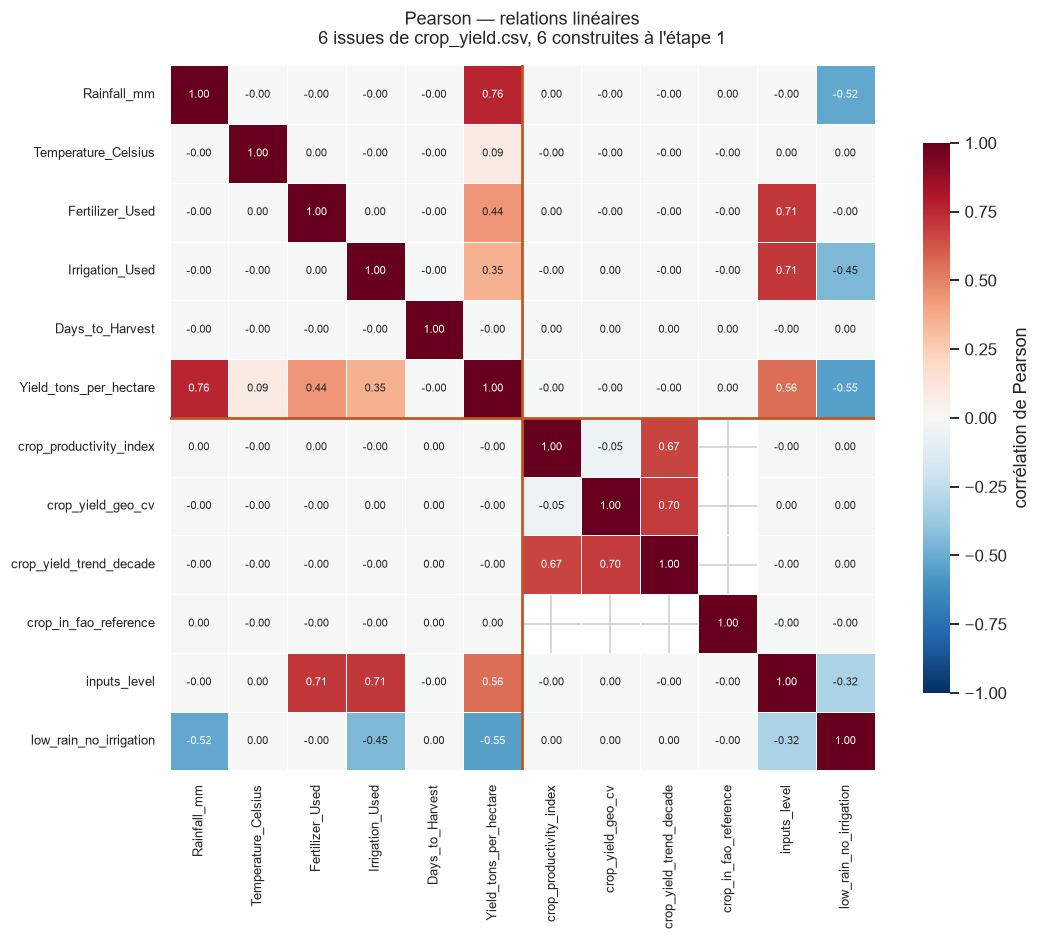

In [29]:
# Les variables creees sont regroupees a droite, pour voir d un coup d oeil
# ce que l etape 1 a ajoute
ordre_p = ([c for c in NUMERIQUES if ORIGINE[c] == 'origine']
           + [c for c in NUMERIQUES if ORIGINE[c] == 'créée'])
n_origine = sum(v == 'origine' for v in ORIGINE.values())

fig, ax = plt.subplots(figsize=(10.5, 8.6))
sns.heatmap(pearson.loc[ordre_p, ordre_p], annot=True, fmt='.2f',
            annot_kws={'size': 7.5}, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.6, linecolor='white',
            cbar_kws={'label': 'corrélation de Pearson', 'shrink': 0.78}, ax=ax)
ax.set_title('Pearson — relations linéaires\n'
             f'{n_origine} issues de crop_yield.csv, '
             f'{len(NUMERIQUES) - n_origine} construites à l\'étape 1',
             fontsize=11.5, pad=14)
ax.tick_params(labelsize=8.5)
# Trait de separation entre variables d origine et variables creees
ax.axhline(n_origine, color=ORANGE, lw=1.8)
ax.axvline(n_origine, color=ORANGE, lw=1.8)
fig.tight_layout()

chemin = PROJECT_ROOT / 'reports' / 'figures' / 'correlation_numeriques.png'
chemin.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(chemin, dpi=130, bbox_inches='tight', facecolor='white')
print('écrit :', chemin.relative_to(PROJECT_ROOT),
      f'— {chemin.stat().st_size / 1024:.0f} Ko')
plt.show()

#### La même matrice en rangs : Spearman

Spearman est le coefficient de Pearson appliqué aux **rangs**. Il vaut 1 pour toute relation croissante, droite ou courbe. Les comparer revient à demander : *ces relations sont-elles droites, ou seulement croissantes ?*

In [30]:
# Spearman : Pearson applique aux rangs. Detecte les relations monotones,
# y compris courbes, que Pearson sous-estime.
spearman = quantitatif.corr(method='spearman')

masque = np.triu(np.ones(pearson.shape), k=1).astype(bool)
comparaison = pd.DataFrame({'pearson': pearson.where(masque).stack(),
                            'spearman': spearman.where(masque).stack()})
# Ecart entre les deux FORCES d association, independamment du signe
comparaison['ecart'] = comparaison['spearman'].abs() - comparaison['pearson'].abs()

fortes = comparaison[comparaison['spearman'].abs() >= SEUIL]
print(f'Paires |Spearman| >= {SEUIL:.2f} : {len(fortes)}  '
      f'(Pearson en comptait {int((comparaison["pearson"].abs() >= SEUIL).sum())})')
for (a, b), ligne in fortes.sort_values('spearman', key=abs, ascending=False).iterrows():
    print(f'  {a:<26} <-> {b:<24} {ligne["spearman"]:+.4f}')

print('\nLes cinq paires ou les deux coefficients divergent le plus :')
print(comparaison.reindex(comparaison['ecart'].abs()
                          .sort_values(ascending=False).index)
                 .head(5).round(4).to_string())

# Les variables FAO ne prennent qu'une valeur par culture : un coefficient de
# rang calcule sur si peu de points distincts n'est pas interpretable.
print('\nNombre de valeurs distinctes, pour relativiser :')
for colonne in NUMERIQUES:
    print(f'  {colonne:<26} {donnees[colonne].nunique():>7,}')

Paires |Spearman| >= 0.70 : 5  (Pearson en comptait 3)
  crop_yield_geo_cv          <-> crop_yield_trend_decade  +0.7997
  crop_productivity_index    <-> crop_yield_trend_decade  +0.7995
  Rainfall_mm                <-> Yield_tons_per_hectare   +0.7694
  Fertilizer_Used            <-> inputs_level             +0.7076
  Irrigation_Used            <-> inputs_level             +0.7076

Les cinq paires ou les deux coefficients divergent le plus :
                                                 pearson  spearman  ecart
crop_productivity_index crop_yield_geo_cv         -0.050     0.399  0.349
                        crop_yield_trend_decade    0.673     0.799  0.127
crop_yield_geo_cv       crop_yield_trend_decade    0.696     0.800  0.103
Yield_tons_per_hectare  inputs_level               0.562     0.544 -0.018
Irrigation_Used         Yield_tons_per_hectare     0.353     0.340 -0.013

Nombre de valeurs distinctes, pour relativiser :
  Rainfall_mm                999,769
  Temperature_Celsius 

écrit : reports\figures\correlation_spearman.png — 127 Ko


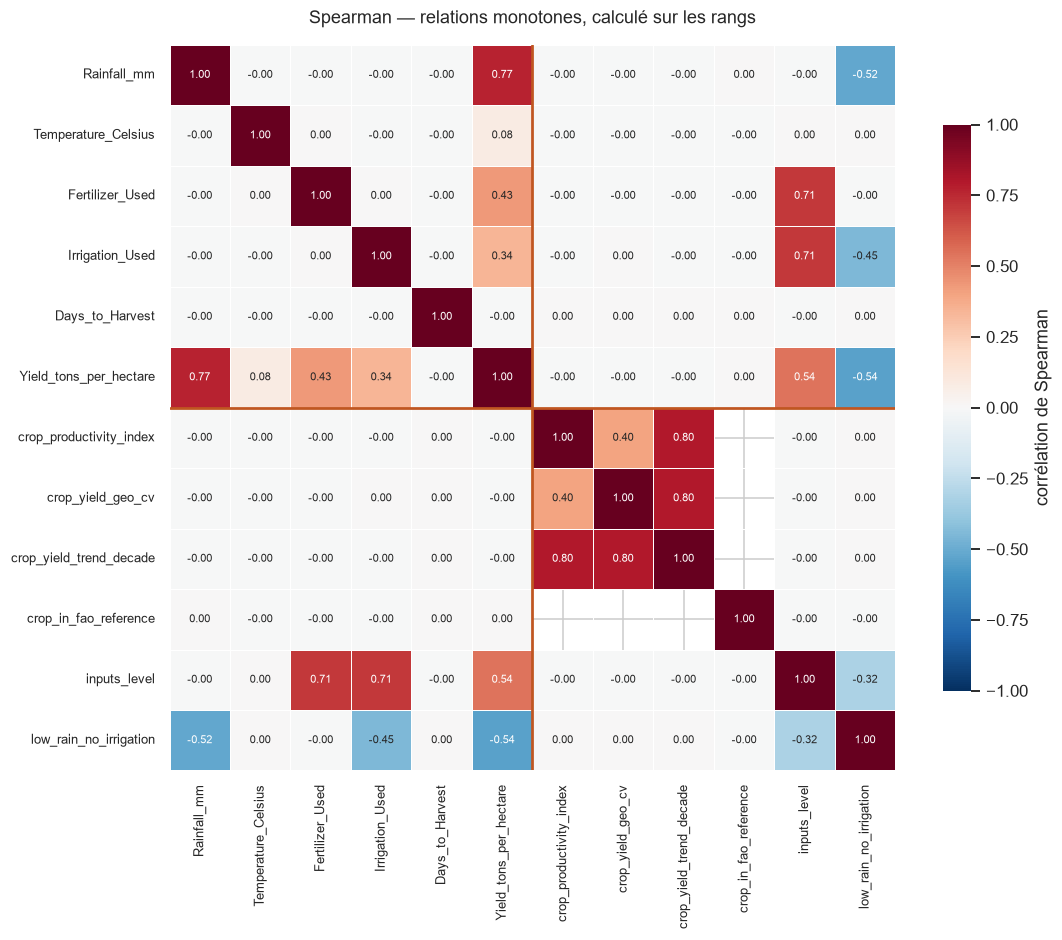

In [31]:
# Seconde figure : la meme matrice, calculee sur les rangs
fig, ax = plt.subplots(figsize=(10.5, 8.6))
sns.heatmap(spearman.loc[ordre_p, ordre_p], annot=True, fmt='.2f',
            annot_kws={'size': 7.5}, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.6, linecolor='white',
            cbar_kws={'label': 'corrélation de Spearman', 'shrink': 0.78}, ax=ax)
ax.set_title('Spearman — relations monotones, calculé sur les rangs',
             fontsize=11.5, pad=14)
ax.tick_params(labelsize=8.5)
# Trait de separation entre variables d origine et variables creees
ax.axhline(n_origine, color=ORANGE, lw=1.8)
ax.axvline(n_origine, color=ORANGE, lw=1.8)
fig.tight_layout()

chemin = PROJECT_ROOT / 'reports' / 'figures' / 'correlation_spearman.png'
fig.savefig(chemin, dpi=130, bbox_inches='tight', facecolor='white')
print('écrit :', chemin.relative_to(PROJECT_ROOT),
      f'— {chemin.stat().st_size / 1024:.0f} Ko')
plt.show()


> **Lecture.** La pluviométrie domine (0,76 avec le rendement), devant la fertilisation (0,44) et l'irrigation (0,35). La température pèse 0,08, la durée de cycle rien.
>
> **Les deux coefficients s'accordent** : moins de 0,013 d'écart sur les quatre facteurs du rendement. Si une relation était courbe, Spearman serait nettement plus élevé. Il ne l'est pas — **ces relations sont droites**.
>
> Une seule paire franchit 0,70 dans les deux méthodes : `inputs_level` avec `Fertilizer_Used` et avec `Irrigation_Used`, à **0,708**. C'est la signature d'une variable qui *est* la somme des deux autres.
>
> **Les divergences entre méthodes ne concernent que les variables FAO**, et elles ne démontrent rien : ces colonnes ne prennent que **quatre valeurs distinctes**, une par culture du référentiel. Sur quatre points, un coefficient de rang vaut 0,80 une fois sur trois par simple hasard — et entre 0,6 et 0,8, aucune autre valeur n'est atteignable. §8.5 l'avait déjà établi.

In [32]:
from scipy.stats import chi2_contingency

# Cette section analyse le dataset tel qu il est AVANT le retrait de la
# section 8.7, soit 16 colonnes. Relire le livrable donnerait une matrice
# amputee de deux variables, dont celle qui motive justement le retrait :
# la section doit donc tourner dans la continuite du notebook.
try:
    donnees = dataset
except NameError:
    raise RuntimeError(
        "`dataset` n est pas en memoire. La section 8.6 analyse les colonnes "
        "telles qu elles existent AVANT le retrait de la section 8.7 : elle ne "
        "peut pas etre executee seule, car le livrable sur disque en compte "
        "deux de moins. Relancer le notebook depuis le debut.") from None

VARIABLES = [c for c in donnees.columns if c != TARGET]
CATEGORIELLES = [c for c in VARIABLES if donnees[c].dtype == object
                 or str(donnees[c].dtype) in ('category', 'str')]
print(f'{len(VARIABLES)} variables explicatives, dont {len(CATEGORIELLES)} categorielles')
print('Categorielles :', CATEGORIELLES)


def rapport_correlation(quantitative, categorielle):
    """Eta : part de la variance de la quantitative expliquee par les groupes."""
    valide = pd.DataFrame({'q': quantitative, 'c': categorielle}).dropna()
    groupes = valide.groupby('c', observed=True)['q'].agg(['mean', 'count'])
    inter = ((groupes['mean'] - valide['q'].mean()) ** 2 * groupes['count']).sum()
    total = ((valide['q'] - valide['q'].mean()) ** 2).sum()
    return np.sqrt(inter / total) if total > 0 else 0.0


def v_cramer(a, b):
    """V de Cramer : association entre deux variables categorielles."""
    table = pd.crosstab(a, b)
    khi2 = chi2_contingency(table)[0]
    n = table.to_numpy().sum()
    return np.sqrt(khi2 / (n * (min(table.shape) - 1)))


# Matrice d association : une mesure adaptee a chaque type de paire
association = pd.DataFrame(np.eye(len(VARIABLES)), index=VARIABLES, columns=VARIABLES)
for i, a in enumerate(VARIABLES):
    for b in VARIABLES[i + 1:]:
        a_cat, b_cat = a in CATEGORIELLES, b in CATEGORIELLES
        if a_cat and b_cat:
            valeur = v_cramer(donnees[a], donnees[b])
        elif a_cat:
            valeur = rapport_correlation(donnees[b].astype(float), donnees[a])
        elif b_cat:
            valeur = rapport_correlation(donnees[a].astype(float), donnees[b])
        else:
            valeur = abs(donnees[[a, b]].astype(float).corr().iloc[0, 1])
        association.loc[a, b] = association.loc[b, a] = valeur

SEUIL = 0.70
paires = (association.where(np.triu(np.ones(association.shape), k=1).astype(bool))
                     .stack().sort_values(ascending=False))
fortes = paires[paires >= SEUIL]

print(f'\nPaires d association >= {SEUIL:.2f} : {len(fortes)}')
for (a, b), valeur in fortes.items():
    print(f'  {a:<26} <-> {b:<24} {valeur:.4f}')

15 variables explicatives, dont 4 categorielles
Categorielles : ['Region', 'Soil_Type', 'Crop', 'Weather_Condition']

Paires d association >= 0.70 : 6
  Crop                       <-> crop_yield_geo_cv        1.0000
  Crop                       <-> crop_productivity_index  1.0000
  Crop                       <-> crop_yield_trend_decade  1.0000
  Crop                       <-> crop_in_fao_reference    1.0000
  Fertilizer_Used            <-> inputs_level             0.7076
  Irrigation_Used            <-> inputs_level             0.7076


écrit : reports\figures\redondance_variables.png — 181 Ko


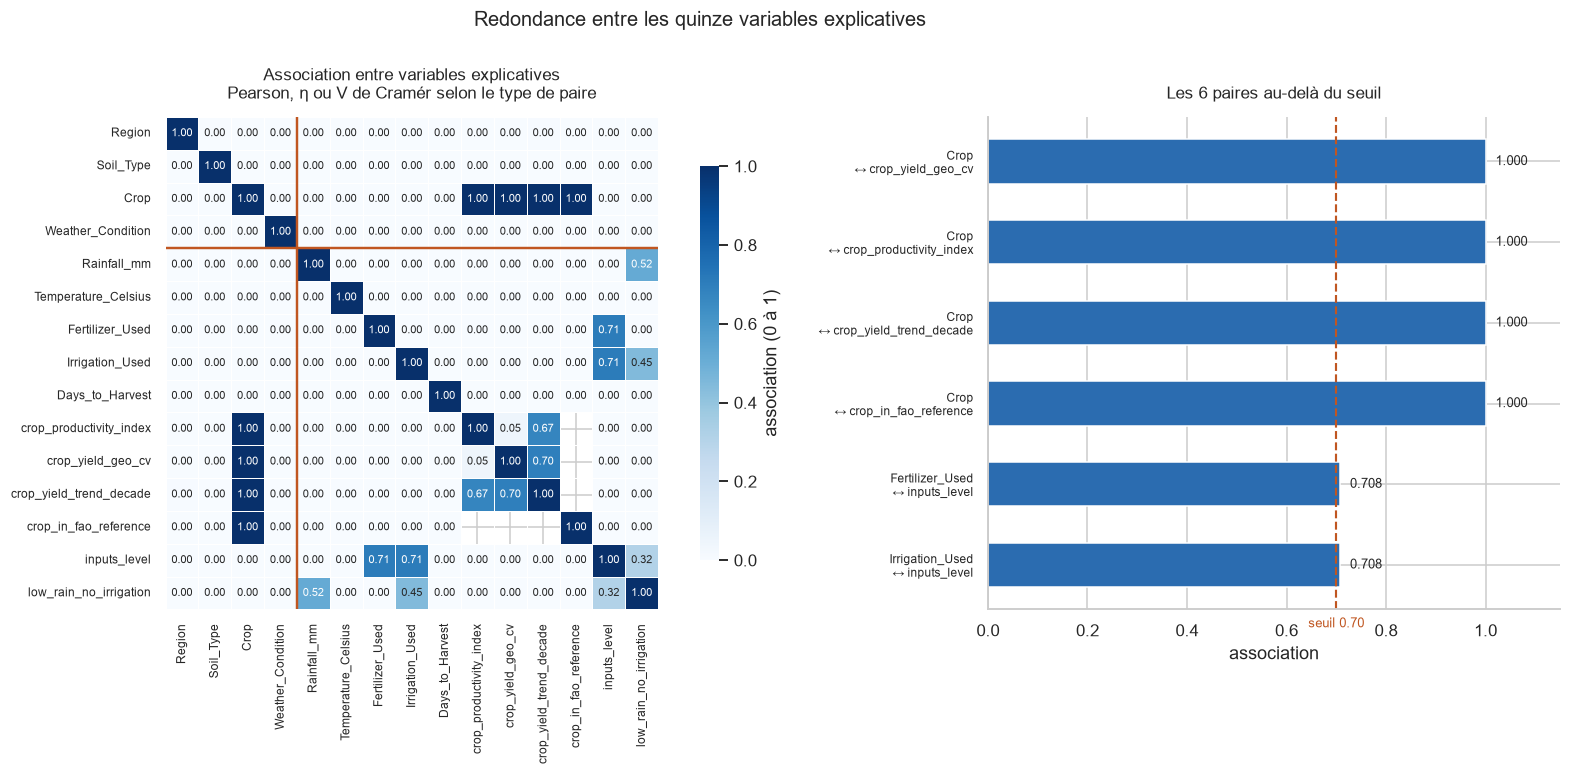

In [33]:
# Figure : matrice d association a gauche, paires au-dela du seuil a droite
ordre = CATEGORIELLES + [c for c in VARIABLES if c not in CATEGORIELLES]
matrice = association.loc[ordre, ordre]

# Les paires indefinies apparaissent en clair : elles surviennent quand une
# colonne devient constante une fois les valeurs manquantes retirees.
etiquettes_cases = matrice.map(lambda v: 'n/d' if pd.isna(v) else f'{v:.2f}')

fig, (gauche, droite) = plt.subplots(
    1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1.45, 1]})

sns.heatmap(matrice, annot=etiquettes_cases, fmt='', annot_kws={'size': 7},
            cmap='Blues', vmin=0, vmax=1, square=True, linewidths=0.6,
            linecolor='white', cbar_kws={'label': 'association (0 à 1)', 'shrink': 0.8},
            ax=gauche)
gauche.set_title("Association entre variables explicatives\n"
                 "Pearson, η ou V de Cramér selon le type de paire",
                 fontsize=11, pad=12)
gauche.tick_params(labelsize=8)
# Trait de separation : les 4 categorielles sont regroupees en haut a gauche
gauche.axhline(len(CATEGORIELLES), color=ORANGE, lw=1.6)
gauche.axvline(len(CATEGORIELLES), color=ORANGE, lw=1.6)

etiquettes = [f'{a}\n↔ {b}' for a, b in fortes.index]
position = np.arange(len(fortes))
droite.barh(position, fortes.to_numpy(), color=BLUE, height=0.55)
droite.set_yticks(position, etiquettes, fontsize=8)
droite.invert_yaxis()
droite.axvline(SEUIL, color=ORANGE, ls='--', lw=1.4)
# Etiquette du seuil en bas du trait, pour ne pas heurter le titre
droite.text(SEUIL, len(fortes) - 0.35, f'seuil {SEUIL:.2f}', color=ORANGE,
            fontsize=8.5, ha='center', va='top')
droite.set_xlim(0, 1.15)
droite.set_xlabel('association')
droite.set_title(f'Les {len(fortes)} paires au-delà du seuil', fontsize=11, pad=12)
for cote in ('top', 'right'):
    droite.spines[cote].set_visible(False)
# Valeur au bout de chaque barre, plus lisible qu une grille lue de travers
for y, valeur in zip(position, fortes.to_numpy()):
    droite.text(valeur + 0.02, y, f'{valeur:.3f}', va='center', fontsize=8.5)

fig.suptitle('Redondance entre les quinze variables explicatives', fontsize=13, y=1.0)
fig.tight_layout()

chemin = PROJECT_ROOT / 'reports' / 'figures' / 'redondance_variables.png'
chemin.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(chemin, dpi=130, bbox_inches='tight', facecolor='white')
print('écrit :', chemin.relative_to(PROJECT_ROOT),
      f'— {chemin.stat().st_size / 1024:.0f} Ko')
plt.show()

In [34]:
# Redondance EXACTE : une variable est-elle reconstituable a partir des autres ?
print('Vérifications exactes, au-delà de la corrélation :\n')

somme = (donnees['Fertilizer_Used'].astype(int)
         + donnees['Irrigation_Used'].astype(int))
print(f"  inputs_level == Fertilizer_Used + Irrigation_Used : "
      f"{bool((donnees['inputs_level'] == somme).all())}")

# Une variable constante par culture est entierement determinee par Crop
print('\n  Nombre de valeurs distinctes par culture :')
for colonne in ['crop_productivity_index', 'crop_yield_geo_cv',
                'crop_yield_trend_decade', 'crop_in_fao_reference']:
    distinctes = donnees.groupby('Crop', observed=True)[colonne].nunique(dropna=False)
    print(f'    {colonne:<26} {distinctes.max()} valeur(s) par culture '
          f'-> {"determinee par Crop" if distinctes.max() <= 1 else "variable"}')

print('\n  low_rain_no_irrigation est un SEUIL, pas une combinaison linéaire :')
seuil_verifie = ((donnees['Rainfall_mm'] < SEUIL_FAIBLE_PLUIE_MM)
                 & ~donnees['Irrigation_Used'])
print(f"    == (Rainfall_mm < {SEUIL_FAIBLE_PLUIE_MM}) & sans irrigation : "
      f"{bool((donnees['low_rain_no_irrigation'] == seuil_verifie).all())}")
print('    -> non reconstituable par régression linéaire, donc conservée')

Vérifications exactes, au-delà de la corrélation :

  inputs_level == Fertilizer_Used + Irrigation_Used : True

  Nombre de valeurs distinctes par culture :
    crop_productivity_index    1 valeur(s) par culture -> determinee par Crop
    crop_yield_geo_cv          1 valeur(s) par culture -> determinee par Crop
    crop_yield_trend_decade    1 valeur(s) par culture -> determinee par Crop
    crop_in_fao_reference      1 valeur(s) par culture -> determinee par Crop

  low_rain_no_irrigation est un SEUIL, pas une combinaison linéaire :
    == (Rainfall_mm < 400) & sans irrigation : True
    -> non reconstituable par régression linéaire, donc conservée


> **Lecture.** Cinq redondances exactes, qu'un seuil de 0,90 sur les seules numériques laissait passer :
>
> - `inputs_level` **est** la somme de `Fertilizer_Used` et `Irrigation_Used`. Elle ne corrèle qu'à 0,71 avec chacune, mais la vérification exacte ne laisse aucun doute ;
> - les **quatre variables de culture** ne prennent qu'une valeur par culture : `Crop` les détermine entièrement, η = 1,00. Invisible à Pearson, qui ignore `Crop`.
>
> Les cases `n/d` : une fois les valeurs manquantes retirées, `crop_in_fao_reference` devient constante et l'association n'est plus définie. La vérification exacte règle le cas.
>
> `low_rain_no_irrigation` fait exception — c'est un **seuil**, donc une transformation non linéaire qu'aucune combinaison linéaire ne reconstitue.
>
> **Seule `inputs_level` est une redondance *exacte entre colonnes du livrable*** : elle sort en §8.7. Les quatre variables de culture restent, et seront **utilisées à l'entraînement** — leur apport se mesure, il ne se présume pas. À garder en tête au moment de lire SHAP : il répartira l'effet « culture » entre `Crop` et ces quatre indicateurs, sans qu'aucun partage ait de sens agronomique.

### 8.7 Deux colonnes retirées du livrable

Deux seulement. Toutes les autres sont conservées : leur contribution au modèle sera **mesurée** à l'entraînement, pas présumée ici.

| Colonne | Motif |
|---|---|
| `inputs_level` | **Redondance exacte** — vaut `Fertilizer_Used + Irrigation_Used` sur toutes les lignes. N'ajoute rien, et empêche d'attribuer un effet à l'une ou l'autre pratique, par coefficient comme par SHAP. |
| `Days_to_Harvest` | **Disponibilité incertaine à la prédiction** (§7.2). Si cette durée est constatée à la récolte, l'agriculteur ne la connaît pas au moment d'interroger l'application. Son pouvoir explicatif étant nul, la conserver n'exposerait à ce risque pour aucun gain. |

Les quatre variables FAO restent malgré leur détermination par `Crop` : elles décrivent le contexte historique de chaque culture et alimentent le rapport métier.

In [ ]:
# Second retrait, apres l'analyse de 8.6 qui le justifie. `preparation.
# reduire_au_livrable` applique les deux d'un coup, dans cet ordre.
avant = dataset.shape[1]
dataset = dataset.drop(columns=COLONNES_NON_RETENUES)
explicatives = [c for c in dataset.columns if c != TARGET]

print(f'Colonnes retirees : {COLONNES_NON_RETENUES}')
print(f'  {avant} colonnes -> {dataset.shape[1]}')
print(f'  {len(explicatives)} variables explicatives + 1 cible\n')
print('Dataset final :')
for colonne in dataset.columns:
    role = 'CIBLE' if colonne == TARGET else 'explicative'
    print(f'  {colonne:<26} {str(dataset[colonne].dtype):<10} {role}')

## 9. Dictionnaire des variables et contrôles

**Ce notebook n'écrit aucun jeu de données.** Il calcule, commente et vérifie ;
l'écriture appartient au script :

```bash
uv run python scripts/prepare_data.py
```

Un seul producteur, donc aucune ambiguïté sur le fichier qui fait foi — et un
« Run All » ne peut pas réécrire `data/processed/` par surprise. Les cellules
ci-dessous confrontent le dataset calculé en mémoire à celui que le script a
produit.

In [ ]:
dictionnaire = preparation.dictionnaire_des_variables()

print('Toutes les colonnes documentées :',
      set(dictionnaire.index) == set(dataset.columns))
dictionnaire

In [ ]:
# `controler` leve si une valeur manquante inattendue subsiste : les seules
# admises sont celles des cultures hors referentiel, et leur nombre se calcule.
resultat = preparation.Preparation(dataset=dataset, panel=panel,
                                   reference=reference, dictionnaire=dictionnaire)
bilan = preparation.controler(resultat)

for libelle, valeur in bilan.items():
    print(f'{libelle.replace("_", " "):<28} {valeur:>12,}')
print()
print('Variables creees :', COLONNES_DIFFUSEES
      + ['crop_in_fao_reference', 'low_rain_no_irrigation'])

In [ ]:
# Confrontation en memoire : aucun fichier n'est cree, pas meme temporaire.
# Le dataset calcule ci-dessus doit etre exactement celui que le script a ecrit.
livrable_present = CONSOLIDATED_PARQUET_PATH.exists()

if not livrable_present:
    print('Livrable absent de data/processed/. Le produire avec :')
    print('    uv run python scripts/prepare_data.py')
else:
    sur_disque = pd.read_parquet(CONSOLIDATED_PARQUET_PATH)
    print('Colonnes identiques :', list(dataset.columns) == list(sur_disque.columns))
    print('Types identiques    :', bool((dataset.dtypes == sur_disque.dtypes).all()))
    print('Valeurs identiques  :', dataset.equals(sur_disque))
    print()
    print('LIVRABLE — data/processed/')
    for chemin in [CONSOLIDATED_PATH, CONSOLIDATED_PARQUET_PATH]:
        print(f'  {chemin.name:<40} {chemin.stat().st_size / 1024 ** 2:>8,.1f} Mo')
    print()
    print('ARTEFACTS — data/interim/')
    for chemin in [DATA_DICTIONARY_PATH, CROP_REFERENCE_PATH, FAO_PANEL_PATH]:
        print(f'  {chemin.name:<40} {chemin.stat().st_size / 1024 ** 2:>8,.2f} Mo')

In [ ]:
# Les deux formats du livrable portent-ils la meme chose, et fidelement ?
# Lecture seule, elle aussi.
if not livrable_present:
    print('Rien a relire : le livrable n\'a pas encore ete produit.')
else:
    import time

    debut = time.perf_counter(); relu_csv = pd.read_csv(CONSOLIDATED_PATH)
    duree_csv = time.perf_counter() - debut
    debut = time.perf_counter(); relu_parquet = pd.read_parquet(CONSOLIDATED_PARQUET_PATH)
    duree_parquet = time.perf_counter() - debut

    numeriques = [c for c in dataset.columns
                  if pd.api.types.is_numeric_dtype(dataset[c])
                  and not pd.api.types.is_bool_dtype(dataset[c])]

    ecart_csv = max(float((relu_csv[c] - dataset[c]).abs().max()) for c in numeriques)
    ecart_parquet = max(float((relu_parquet[c] - dataset[c]).abs().max()) for c in numeriques)

    print('Colonnes identiques      :', list(relu_csv.columns) == list(dataset.columns))
    print('Types preserves (CSV)    :', bool((relu_csv.dtypes == dataset.dtypes).all()))
    print('Types preserves (Parquet):', bool((relu_parquet.dtypes == dataset.dtypes).all()))
    print('Manquants conformes      :',
          int(relu_parquet.isna().sum().sum())
          == int(relu_parquet[COLONNES_DIFFUSEES].isna().sum().sum()))
    print()
    print(f'Ecart maximal a la source — CSV     : {ecart_csv:.2e}')
    print(f'Ecart maximal a la source — Parquet : {ecart_parquet:.2e}')
    print()
    print(f'Lecture CSV     : {duree_csv:5.1f} s')
    print(f'Lecture Parquet : {duree_parquet:5.1f} s   '
          f'({duree_csv / duree_parquet:.0f}x plus rapide)')

> **Les deux formats ne sont pas strictement équivalents.** Le Parquet reproduit les valeurs **à l'identique**, tandis que le CSV introduit un écart d'arrondi de l'ordre de **10⁻¹⁴** : l'écriture décimale ne restitue pas exactement tous les bits d'un flottant.
>
> L'écart est sans conséquence pratique — il porte sur la quatorzième décimale d'une pluviométrie en millimètres. Mais il justifie de **travailler sur le Parquet** dans les étapes suivantes : 5 fois plus compact, 8 fois plus rapide à lire, types préservés, et fidèle au bit près.
>
> Le CSV reste le livrable demandé par la mission, et les deux fichiers portent exactement les mêmes données aux arrondis près.

## 10. Figures du rapport métier

Quatre figures destinées au document de synthèse, générées ici pour rester reproductibles. Elles sont écrites dans `reports/figures/`.

In [40]:
from matplotlib.patches import FancyBboxPatch

DOSSIER_FIGURES = PROJECT_ROOT / 'reports' / 'figures'
DOSSIER_FIGURES.mkdir(parents=True, exist_ok=True)


def enregistrer(figure, nom):
    chemin = DOSSIER_FIGURES / nom
    figure.savefig(chemin, dpi=130, bbox_inches='tight', facecolor='white')
    print('écrit :', chemin.relative_to(PROJECT_ROOT), '—',
          f'{chemin.stat().st_size / 1024:.0f} Ko')

### 10.1 Pourquoi il n'y a pas eu de jointure

In [ ]:
def boite(ax, x, y, largeur, hauteur, titre, detail, couleur,
          alpha=0.13, taille_titre=10, taille_detail=8.3):
    ax.add_patch(FancyBboxPatch((x, y), largeur, hauteur, boxstyle="round,pad=0.010",
                                linewidth=1.6, edgecolor=couleur,
                                facecolor=couleur, alpha=alpha, zorder=2))
    ax.text(x + largeur / 2, y + hauteur * 0.68, titre, ha="center", va="center",
            fontsize=taille_titre, fontweight="bold", color="#1b1f24", zorder=3)
    ax.text(x + largeur / 2, y + hauteur * 0.27, detail, ha="center", va="center",
            fontsize=taille_detail, color="#4a5560", zorder=3)


def fleche(ax, depart, arrivee, couleur, style="-|>", largeur=1.7, courbure=0.0, tirets=None):
    ax.annotate("", xy=arrivee, xytext=depart,
                arrowprops=dict(arrowstyle=style, color=couleur, linewidth=largeur,
                                linestyle=tirets or "solid",
                                connectionstyle=f"arc3,rad={courbure}"))


fig, ax = plt.subplots(figsize=(14, 9))
ax.set(xlim=(0, 1), ylim=(0, 1))
ax.axis("off")

# ----- Les quatre sources historiques -----
sources = [("yield.csv", "rendements\n56 717 obs."),
           ("temp.csv", "températures\nà agréger"),
           ("rainfall.csv", "pluviométrie\nnormale par pays"),
           ("pesticides.csv", "volumes\nnationaux")]
for k, (nom, detail) in enumerate(sources):
    boite(ax, 0.555 + k * 0.112, 0.855, 0.100, 0.115, nom, detail, GREEN,
          taille_titre=9, taille_detail=7.6)
    fleche(ax, (0.605 + k * 0.112, 0.852), (0.775, 0.795), GREEN, "-", 1.0)

ax.text(0.775, 0.836, "jointures gauches sur  pays + année", ha="center",
        fontsize=8.8, fontweight="bold", color=GREEN, zorder=4, bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none"))

boite(ax, 0.545, 0.645, 0.44, 0.145, "Panel FAO consolidé",
      "56 709 observations · granularité  pays × année × culture", GREEN, alpha=0.20)

fleche(ax, (0.765, 0.642), (0.765, 0.565), GREEN)
ax.text(0.785, 0.603, "agrégation par culture", fontsize=8.8, color=GREEN, ha="left")

boite(ax, 0.595, 0.430, 0.34, 0.130, "Référentiel par culture",
      "4 lignes · 1 ligne par culture · clé : Crop\nproductivité, variabilité, tendance", GREEN)

# ----- Le jeu de parcelles -----
boite(ax, 0.035, 0.620, 0.325, 0.150, "crop_yield.csv",
      "1 000 000 parcelles · clé : Crop\nculture · climat · pratiques · rendement", BLUE)
ax.text(0.150, 0.585, "granularité : la parcelle — ni pays, ni année", ha="center",
        fontsize=8.5, style="italic", color="#c0484b")

# ----- Le fichier ecarte -----
boite(ax, 0.035, 0.855, 0.325, 0.115, "yield_df.csv  —  écarté",
      "13 130 observations réelles sur 56 717 (−77 %)\n28 242 lignes dont 15 112 répétitions",
      "#8a8f96", alpha=0.10, taille_titre=9.5, taille_detail=7.6)
ax.plot([0.06, 0.335], [0.962, 0.863], color="#8a8f96", linewidth=1.3)

# ----- La frontiere : elle ne descend pas jusqu'a la convergence -----
ax.plot([0.455, 0.455], [0.42, 0.985], color="#c0484b", linestyle=(0, (6, 5)), linewidth=1.5)
ax.text(0.455, 0.930, "AUCUNE CLÉ\nGÉOGRAPHIQUE\nNI TEMPORELLE", ha="center", va="center",
        fontsize=9.5, fontweight="bold", color="#c0484b",
        bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor="none"))
ax.text(0.455, 0.470, "la seule clé partagée\nest le type de culture", ha="center", va="center",
        fontsize=8.5, color="#c0484b", style="italic",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="none"))

# ----- La convergence vers le livrable -----
boite(ax, 0.225, 0.075, 0.55, 0.150, "crop_yield_consolidated.csv",
      "999 769 lignes × 14 colonnes · 6 cultures conservées\n231 rendements impossibles exclus · cible inchangée",
      ORANGE, alpha=0.14, taille_titre=11, taille_detail=8.6)

fleche(ax, (0.312, 0.616), (0.385, 0.232), ORANGE, largeur=2.1, courbure=-0.14)
fleche(ax, (0.765, 0.426), (0.640, 0.230), ORANGE, largeur=2.1, courbure=0.12)

ax.text(0.500, 0.300, "JOINTURE GAUCHE SUR  Crop", ha="center",
        fontsize=10, fontweight="bold", color=ORANGE, zorder=4, bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none"))
ax.text(0.500, 0.265, "plusieurs parcelles → une seule ligne de référence\n"
                      "4 cultures appariées sur 6 · aucune parcelle dupliquée",
        ha="center", fontsize=8.5, color="#4a5560", zorder=4, bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none"))

ax.set_title("Comment le jeu de données final est construit", fontsize=14,
             fontweight="bold", pad=16)
enregistrer(fig, "strategie_assemblage.png")
plt.show()

### 10.2 Les leviers du rendement

écrit : reports\figures\leviers_rendement.png — 72 Ko


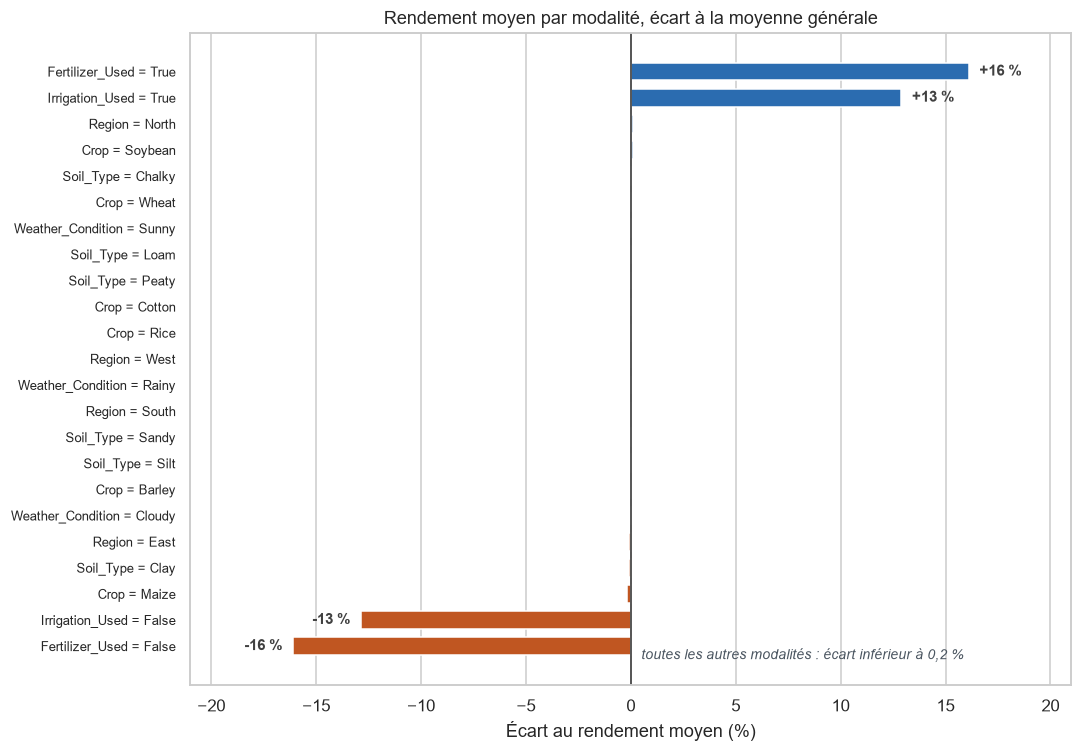

In [42]:
moyenne = dataset[TARGET].mean()
leviers = []
for variable in ['Fertilizer_Used', 'Irrigation_Used'] + CAT_BRUTES:
    moyennes = dataset.groupby(variable, observed=True)[TARGET].mean()
    for modalite, valeur in moyennes.items():
        leviers.append({'libelle': f'{variable} = {modalite}',
                        'ecart_pct': 100 * (valeur / moyenne - 1)})

leviers = pd.DataFrame(leviers).sort_values('ecart_pct')

fig, ax = plt.subplots(figsize=(10, 7))
couleurs = [BLUE if v >= 0 else ORANGE for v in leviers['ecart_pct']]
ax.barh(range(len(leviers)), leviers['ecart_pct'], color=couleurs, height=0.68)
ax.set_yticks(range(len(leviers)))
ax.set_yticklabels(leviers['libelle'], fontsize=8.5)
ax.axvline(0, color='0.3', linewidth=1.2)
ax.set(xlabel='Écart au rendement moyen (%)', xlim=(-21, 21),
       title='Rendement moyen par modalité, écart à la moyenne générale')
ax.grid(axis='y', visible=False)

for position, valeur in enumerate(leviers['ecart_pct']):
    if abs(valeur) > 1:
        ax.annotate(format(valeur, '+.0f') + ' %', (valeur, position),
                    xytext=(7 if valeur > 0 else -7, 0), textcoords='offset points',
                    va='center', ha='left' if valeur > 0 else 'right',
                    fontsize=9.5, fontweight='bold', color='0.25')

ax.text(0.5, -0.5, 'toutes les autres modalités : écart inférieur à 0,2 %',
        fontsize=9, style='italic', color='#4a5560')
fig.tight_layout()
enregistrer(fig, 'leviers_rendement.png')
plt.show()

### 10.3 Ce que coûtait le fichier pré-assemblé

écrit : reports\figures\perte_donnees.png — 52 Ko


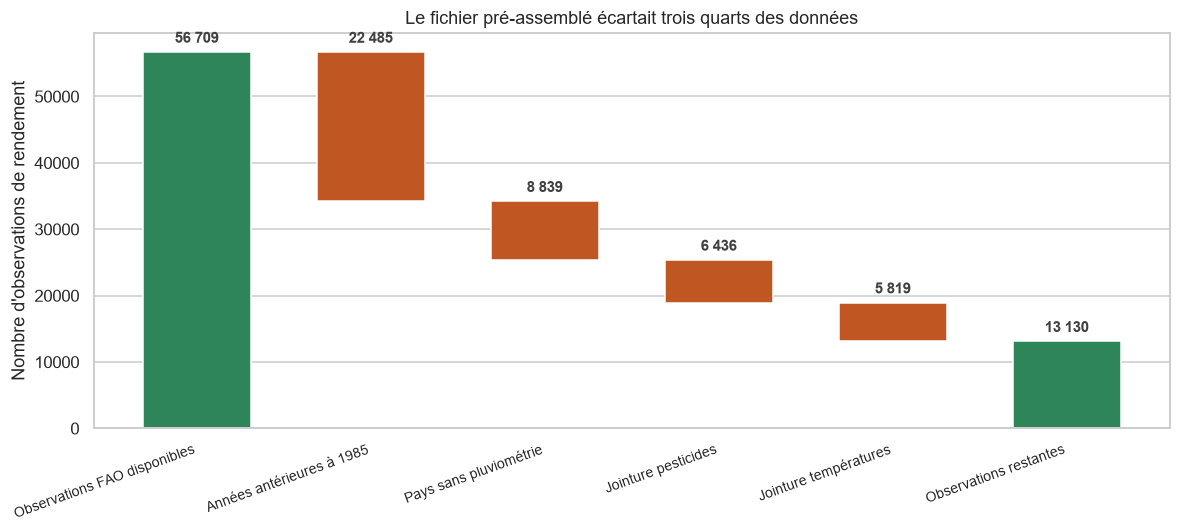

In [43]:
# Recalcul de la cascade de pertes, depuis les fichiers sources
depart = len(rendements)
debut_pluie = pluie['Year'].min()
hors_plage = int((rendements['Year'] < debut_pluie).sum())
apres_pluie = rendements.merge(pluie, on=['Area', 'Year'])
apres_pest = apres_pluie.merge(pesticides, on=['Area', 'Year'])
cles_finales = (apres_pest.merge(temperatures, on=['Area', 'Year'])
                .drop_duplicates(subset=KEY_FAO).shape[0])

etapes = [
    ('Observations FAO disponibles', depart),
    (f'Années antérieures à {debut_pluie}', -hors_plage),
    ('Pays sans pluviométrie', -(depart - hors_plage - len(apres_pluie))),
    ('Jointure pesticides', -(len(apres_pluie) - len(apres_pest))),
    ('Jointure températures', -(len(apres_pest) - cles_finales)),
    ('Observations restantes', cles_finales),
]

fig, ax = plt.subplots(figsize=(11, 5))
base, positions, hauteurs, couleurs = 0, [], [], []
for k, (libelle, valeur) in enumerate(etapes):
    if k in (0, len(etapes) - 1):
        positions.append(0); hauteurs.append(valeur); couleurs.append(GREEN)
        base = valeur if k == 0 else base
    else:
        base += valeur
        positions.append(base); hauteurs.append(-valeur); couleurs.append(ORANGE)

ax.bar(range(len(etapes)), hauteurs, bottom=positions, color=couleurs, width=0.62)
ax.set_xticks(range(len(etapes)))
ax.set_xticklabels([e[0] for e in etapes], rotation=20, ha='right', fontsize=9)
ax.set(ylabel="Nombre d'observations de rendement",
       title='Le fichier pré-assemblé écartait trois quarts des données')
ax.grid(axis='x', visible=False)

for k, (libelle, valeur) in enumerate(etapes):
    sommet = positions[k] + hauteurs[k]
    ax.annotate(format(abs(valeur), ',d').replace(',', ' '),
                (k, sommet), xytext=(0, 6), textcoords='offset points',
                ha='center', fontsize=9.5, fontweight='bold', color='0.25')

fig.tight_layout()
enregistrer(fig, 'perte_donnees.png')
plt.show()

### 10.4 Des rendements très proches entre cultures

écrit : reports\figures\cultures_indiscernables.png — 34 Ko


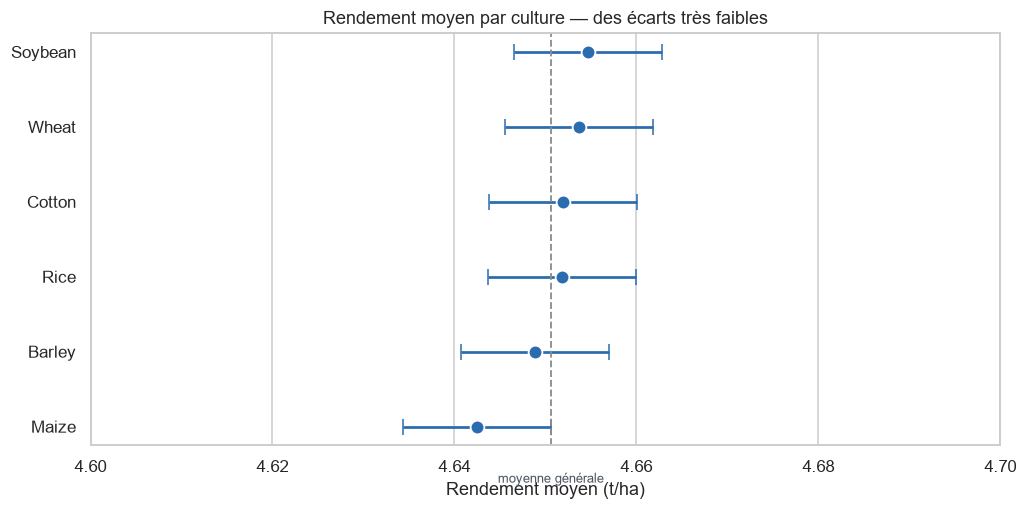

In [44]:
stats_cultures = dataset.groupby('Crop', observed=True)[TARGET].agg(['mean', 'std', 'count'])
stats_cultures['ic95'] = 1.96 * stats_cultures['std'] / np.sqrt(stats_cultures['count'])
stats_cultures = stats_cultures.sort_values('mean')

fig, ax = plt.subplots(figsize=(9.5, 4.8))
positions = np.arange(len(stats_cultures))
ax.errorbar(stats_cultures['mean'], positions, xerr=stats_cultures['ic95'],
            fmt='none', ecolor=BLUE, elinewidth=1.8, capsize=5, zorder=2)
ax.plot(stats_cultures['mean'], positions, 'o', color=BLUE, markersize=9,
        markeredgecolor='white', markeredgewidth=1.2, linestyle='none', zorder=3)

ax.axvline(dataset[TARGET].mean(), color='0.55', linestyle='--', linewidth=1.2)
ax.set_yticks(positions)
ax.set_yticklabels(stats_cultures.index)
ax.set(xlabel='Rendement moyen (t/ha)', xlim=(4.60, 4.70),
       title='Rendement moyen par culture — des écarts très faibles')
ax.grid(axis='y', visible=False)
ax.text(dataset[TARGET].mean(), -0.75, 'moyenne générale', ha='center',
        fontsize=8.5, color='#4a5560')

fig.tight_layout()
enregistrer(fig, 'cultures_indiscernables.png')
plt.show()

### 10.5 Ce que montre l'analyse en composantes principales

écrit : reports\figures\acp_variables.png — 80 Ko


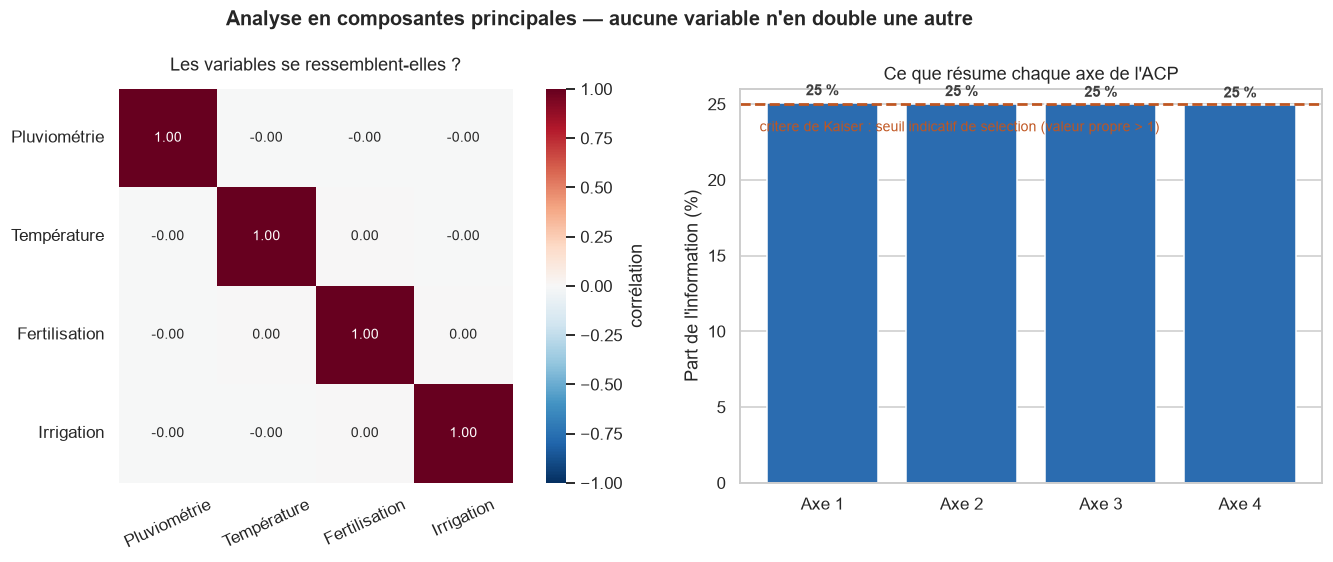

In [45]:
# Deux facons de montrer la meme chose : la matrice de correlation (intuitive)
# et l'eboulis de l'ACP (la mesure formelle)
VARIABLES_ACP = ['Rainfall_mm', 'Temperature_Celsius',
                 'Fertilizer_Used', 'Irrigation_Used']
ETIQUETTES = ['Pluviométrie', 'Température', 'Fertilisation', 'Irrigation']

donnees_acp = dataset[VARIABLES_ACP].astype(float)
matrice = donnees_acp.corr()
acp_rapport = PCA().fit(StandardScaler().fit_transform(donnees_acp))
inerties = 100 * acp_rapport.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2),
                         gridspec_kw={'width_ratios': [1.15, 1]})

sns.heatmap(matrice, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={'label': 'corrélation'}, ax=axes[0],
            xticklabels=ETIQUETTES, yticklabels=ETIQUETTES, annot_kws={'fontsize': 9})
axes[0].set_title('Les variables se ressemblent-elles ?', fontsize=11.5, pad=12)
axes[0].tick_params(axis='x', rotation=25)
axes[0].tick_params(axis='y', rotation=0)

axes[1].bar([f'Axe {i}' for i in range(1, len(inerties) + 1)], inerties, color=BLUE)
axes[1].axhline(100 / len(inerties), color=ORANGE, linestyle='--', linewidth=1.8)
axes[1].text(-0.45, 23.2, 'critere de Kaiser : seuil indicatif de selection (valeur propre > 1)',
             fontsize=9, color=ORANGE, ha='left')
axes[1].set(ylabel="Part de l'information (%)", ylim=(0, 26),
            title="Ce que résume chaque axe de l'ACP")
axes[1].grid(axis='x', visible=False)
for k, valeur in enumerate(inerties):
    axes[1].annotate(f'{valeur:.0f} %', (k, valeur), xytext=(0, 5),
                     textcoords='offset points', ha='center',
                     fontsize=9.5, fontweight='bold', color='0.25')

fig.suptitle("Analyse en composantes principales — aucune variable n'en double une autre",
             fontsize=13, fontweight='bold')
fig.tight_layout()
enregistrer(fig, 'acp_variables.png')
plt.show()

> Ces quatre figures sont référencées dans `reports/data_preparation_summary.md`. Les régénérer suffit à mettre le rapport à jour.

## 11. Synthèse

### Les six variables créées

| # | Variable | Niveau | Statut | Au livrable |
|---|---|---|---|---|
| 1 | `crop_productivity_index` | Culture | Indice relatif **partiellement** normalisé — effet pays réduit, pas annulé | oui |
| 2 | `crop_yield_geo_cv` | Culture | **Variabilité géographique**, pas un risque parcellaire | oui |
| 3 | `crop_yield_trend_decade` | Culture | Tendance descriptive, sensible au périmètre | oui |
| 4 | `crop_in_fao_reference` | Culture | Rend lisibles les valeurs manquantes | oui |
| 5 | `inputs_level` | Parcelle | Somme exacte de deux colonnes présentes | **non — §8.7** |
| 6 | `low_rain_no_irrigation` | Parcelle | Indicateur descriptif, seuil conventionnel | oui |

Avec `Days_to_Harvest`, deux colonnes sortent du livrable (§8.7). Le dataset final compte **14 colonnes : 13 variables explicatives et la cible**, toutes utilisées à l'entraînement.

Les quatre variables de culture sont **entièrement déterminées par `Crop`** (η = 1,00). Elles restent au livrable et au modèle, mais ce partage d'information fausse toute lecture de leurs contributions individuelles — coefficients comme SHAP.

**Quatre autres variables ont été construites puis écartées.** Deux comparaient une température de parcelle à une moyenne annuelle nationale, grandeurs non commensurables (§7.3). Deux étaient redondantes avec celles retenues ; elles restent dans `crop_reference.csv`.

### Ce que la validation établit

Hors échantillon, catégorielles comprises, les quatre jeux de variables donnent le **même R² ≈ 0,913 et le même RMSE ≈ 0,50**. La référence non paramétrique de §8.2 va dans le même sens : stratifier en plus par culture **dégrade** la performance.

Aucun test n'a mis en évidence d'effet exploitable de la culture. Ce n'est pas une démonstration qu'aucun modèle n'y parviendrait, mais le faisceau est serré.

### À trancher à l'étape de modélisation

**La différenciation entre cultures.** L'application doit classer les cultures ; les données n'en portent pas l'information. Deux voies, et le choix est **métier** :

1. **Injecter une calibration externe** depuis le référentiel FAO, en la documentant comme une hypothèse de transfert — à évaluer, non à supposer ;
2. **Renoncer au classement différencié** et présenter l'application comme un prédicteur de rendement.

**Aucune calibration n'est appliquée ici** : la cible exportée est identique à l'originale (§9). Même principe pour l'imputation des cultures sans référence, laissée au pipeline et ajustée sur `train` seul.

### Limites à porter au rapport métier

L'indice compare des **tonnages**, pas des valeurs économiques : la rentabilité dépend de prix et de coûts dont aucune donnée n'est fournie. Le classement devra être présenté comme un classement de **rendement physique**.

Et les variables climatiques décrivent une **saison observée**. L'application est donc un **simulateur de rendement sous conditions renseignées**, non une prévision avant semis.